## Подготовка


In [ ]:
import os
import time
import warnings
from contextlib import redirect_stdout, redirect_stderr
from os import devnull

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
)
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    make_scorer,
)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.pipeline import Pipeline as SkPipeline

from imblearn.datasets import fetch_datasets
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, BorderlineSMOTE
from imblearn.under_sampling import InstanceHardnessThreshold
from imblearn.combine import SMOTETomek
from imblearn.under_sampling import TomekLinks

import umap
import trimap
import pacmap
from IPython.display import display

%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)

plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 10,
    "axes.titlesize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "#fbfbfb",
    "axes.edgecolor": "#d9d9d9",
    "axes.linewidth": 0.8,
})

SEED = 42
# Повторная 5-кратная стратифицированная кросс-валидация: 5 фолдов, 3 повтора.
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
PLOT_LIMIT = 2500

MAIN_COLOR = "#8aa0b2"   # класс −1
RARE_COLOR = "#e11d48"   # класс +1
BA_COLOR = "#345995"
F1_COLOR = "#e11d48"
METHODS = ["t-SNE", "UMAP", "TriMap", "PaCMAP"]

# Бинарная задача: F1 считается по редкому классу +1.
# balanced_accuracy_score(..., adjusted=False) — и для бинарного, и для многоклассового случая.
F1_SCORER = make_scorer(f1_score, average="binary", pos_label=1, zero_division=0)
BA_SCORER = make_scorer(balanced_accuracy_score, adjusted=False)
SCORING = {"Balanced Accuracy": BA_SCORER, "F1-score": F1_SCORER}

# Считаем количнство объектов в каждом классе(-1 и +1)
def class_counts(y):
    labels, counts = np.unique(y, return_counts=True)
    found = dict(zip(labels.tolist(), counts.tolist()))
    return int(found.get(-1, 0)), int(found.get(1, 0))

# Возвращает строку с отношением количества объектов в классе -1 к количеству объектов в классе +1
def ratio_text(y):
    n_maj, n_min = class_counts(y)
    if n_min == 0:
        return "нет класса +1"
    return f"{n_maj / n_min:.1f} : 1"

# Возвращает кортеж из двух значений метрик: balanced accuracy и F1-score
def metric_pair(y_true, y_pred):
    ba = balanced_accuracy_score(y_true, y_pred, adjusted=False)
    f1 = f1_score(y_true, y_pred, average="binary", pos_label=1, zero_division=0)
    return float(ba), float(f1)

## По имени собираем 1 из 3 классификаторов с фиксированными настройками 
def clf_factory(name):
    # Веса классов не включаем: иначе эффект сэмплинга смешается с перевзвешиванием.
    if name == "kNN":
        return KNeighborsClassifier(n_neighbors=5)
    if name == "SVM":
        return SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED)
    if name == "RF":
        return RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1)
    raise KeyError(name)


CLF_NAMES = ["kNN", "SVM", "RF"]

# Последовательное выполнение: скейлер, сэмплинг, классификатор 
def make_model(sampler_spec, clf):
    """Скейлер внутри конвейера, сэмплинг только на обучении, классификатор в конце."""
    steps = [("scaler", StandardScaler())]
    if isinstance(sampler_spec, list):
        steps.extend(sampler_spec)
        return ImbPipeline(steps + [("clf", clf)])
    if sampler_spec is not None:
        steps.append(("sample", sampler_spec))
        return ImbPipeline(steps + [("clf", clf)])
    return SkPipeline(steps + [("clf", clf)])

## Один раз прогоняем алгоритм сэмплинга по уже поданной матрице признаков и вектору меток
def apply_sampler(sampler_spec, X, y):
    if sampler_spec is None:
        return X, y
    if isinstance(sampler_spec, list):
        return ImbPipeline(sampler_spec).fit_resample(X, y)
    return sampler_spec.fit_resample(X, y)

# Если в матрице признаков больше 2500 строк, то берем случайные 2500 строк (для рисунков)
def take_for_plot(X, y, limit=PLOT_LIMIT):
    y = np.asarray(y)
    if len(y) <= limit:
        return np.asarray(X), y
    _, counts = np.unique(y, return_counts=True)
    stratify = y if counts.min() >= 2 else None
    idx, _ = train_test_split(
        np.arange(len(y)), train_size=limit, random_state=SEED, stratify=stratify,
    )
    return np.asarray(X)[idx], y[idx]

## Рисуем точки. Подпись класса задаётся здесь же, легенда берётся из этих подписей.
def draw(ax, Y, labels):
    labels = np.asarray(labels)
    size_maj, size_rare = (8, 18) if len(labels) > 1200 else (16, 32)
    minority = labels == 1
    majority = labels == -1
    if majority.any():
        ax.scatter(
            Y[majority, 0], Y[majority, 1], s=size_maj, c=MAIN_COLOR, marker="o",
            alpha=0.5, linewidths=0, rasterized=True, label="класс −1",
        )
    if minority.any():
        ax.scatter(
            Y[minority, 0], Y[minority, 1], s=size_rare, c=RARE_COLOR, marker="^",
            alpha=0.9, linewidths=0, rasterized=True, zorder=2, label="класс +1",
        )
    ax.legend(frameon=False, fontsize=7, loc="upper right")
    ax.set_xticks([])
    ax.set_yticks([])

## Убираем дубликаты параметров из списка вложения 
def _dedup(pairs):
    out, seen = [], set()
    for label, params in pairs:
        key = tuple(sorted((str(k), str(v)) for k, v in params.items()))
        if key in seen:
            continue
        seen.add(key)
        out.append((label, params))
    return out

## Три сочетания параметров для сжатия данных в 2D. Если точек мало, соседство подрезается под размер облака.
def embedding_settings(n):
    hi = max(2, n - 2)

    perplexities = [p for p in (5, 30, 50) if 1 < p < n]
    if len(perplexities) < 3:
        for p in (max(2, n // 8), max(2, n // 5), max(2, n // 3)):
            if 1 < p < n and p not in perplexities:
                perplexities.append(int(p))
    tsne = [(f"perplexity={int(p)}", {"perplexity": int(p)}) for p in perplexities[:3]]

    umap_pairs = []
    for k, dist in ((5, 0.0), (15, 0.1), (40, 0.5)):
        kk = int(max(2, min(k, hi)))
        umap_pairs.append((f"соседей {kk}, min_dist {dist:g}", {"n_neighbors": kk, "min_dist": dist}))

    trimap_pairs = []
    for nin, nout, label in (
        (4, 2, "inliers 4, outliers 2"),
        (10, 5, "по умолчанию"),
        (12, 5, "inliers 12, outliers 5"),
    ):
        if nin + nout >= n:
            nin = max(2, n // 5)
            nout = max(1, n // 10)
            label = f"inliers {nin}, outliers {nout}"
        if label == "по умолчанию" and n > 20:
            trimap_pairs.append((label, {}))
        else:
            trimap_pairs.append((label, {"n_inliers": int(nin), "n_outliers": int(nout)}))

    pac_pairs = []
    for k, extra, label in (
        (5, {}, "соседей 5"),
        (10, {}, "соседей 10"),
        (10, {"MN_ratio": 2.0, "FP_ratio": 1.0}, "MN=2, FP=1"),
    ):
        kk = int(max(2, min(k, hi)))
        params = {"n_neighbors": kk, **extra}
        text = label if kk == k else f"соседей {kk}" + ("" if not extra else ", MN=2, FP=1")
        pac_pairs.append((text, params))

    return {
        "t-SNE": _dedup(tsne),
        "UMAP": _dedup(umap_pairs),
        "TriMap": _dedup(trimap_pairs),
        "PaCMAP": _dedup(pac_pairs),
    }

## Сжимаем данные в 2D методами t-SNE, UMAP, TriMap, PaCMAP на выбор
def embed(method, X, **params):
    np.random.seed(SEED)
    X64 = np.ascontiguousarray(X, dtype=np.float64)
    with open(devnull, "w") as sink, redirect_stdout(sink), redirect_stderr(sink):
        if method == "t-SNE":
            Y = TSNE(
                n_components=2, random_state=SEED, max_iter=750,
                init="pca", learning_rate="auto", **params,
            ).fit_transform(X64)
        elif method == "UMAP":
            Y = umap.UMAP(n_components=2, random_state=SEED, n_jobs=1, **params).fit_transform(X64)
        elif method == "TriMap":
            Y = trimap.TRIMAP(n_dims=2, **params).fit_transform(X64)
        else:
            model = pacmap.PaCMAP(n_components=2, random_state=SEED, **params)
            Y = model.fit_transform(np.ascontiguousarray(X64, dtype=np.float32))
    return np.asarray(Y)

## Проходим по всем методам сжатия и сохраняем результаты считаем время и ошибки
def compute_grid(X, y):
    stored = {}
    for method, pairs in embedding_settings(len(y)).items():
        stored[method] = []
        for label, params in pairs:
            started = time.time()
            try:
                Y = embed(method, X, **params)
                error = ""
            except Exception as exc:
                Y = None
                error = f"{type(exc).__name__}: {exc}"
            seconds = time.time() - started
            stored[method].append((label, Y, error, seconds))
            status = f"ошибка: {error}" if error else "ок"
            print(f"  {method:<7} | {label:<32} | {seconds:5.1f} с | {status}")
    return stored

## Рисуем сетку вложений(Draw делает точки)
def show_embedding_grid(title, stored, labels):
    fig, axes = plt.subplots(4, 3, figsize=(11.4, 12.4))
    for i, method in enumerate(METHODS):
        items = stored.get(method, [])
        for j in range(3):
            ax = axes[i, j]
            if j >= len(items):
                ax.axis("off")
                continue
            label, Y, error, seconds = items[j]
            if error or Y is None:
                ax.text(0.5, 0.5, error, ha="center", va="center", wrap=True, fontsize=7)
                ax.set_axis_off()
                ax.set_title(label, fontsize=8)
                continue
            draw(ax, Y, labels)
            ax.set_title(f"{label}\n{seconds:.0f} с", fontsize=8)
        axes[i, 0].set_ylabel(method, fontsize=10)
    fig.suptitle(title, fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0.035, 1, 0.96))
    plt.show()

##Рисуем столбчатую диаграмму качества 
def metric_bars(frame, title):
    """Столбцы: по горизонтали классификатор и сэмплинг, по вертикали две метрики."""
    fig_w = max(8.5, 0.48 * len(frame) + 2.2)
    fig, ax = plt.subplots(figsize=(fig_w, 4.4))
    x = np.arange(len(frame))
    width = 0.38
    ba = frame["Balanced Accuracy"].to_numpy(dtype=float)
    f1 = frame["F1-score"].to_numpy(dtype=float)
    ba_err = frame["BA std"].to_numpy(dtype=float) if "BA std" in frame.columns else None
    f1_err = frame["F1 std"].to_numpy(dtype=float) if "F1 std" in frame.columns else None
    ax.bar(x - width / 2, ba, width, yerr=ba_err, capsize=2, label="Balanced Accuracy", color=BA_COLOR)
    ax.bar(x + width / 2, f1, width, yerr=f1_err, capsize=2, label="F1-score", color=F1_COLOR)
    ax.set_xticks(x, frame.index, rotation=55, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("значение метрики")
    ax.set_xlabel("классификатор")
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    plt.show()

##  оверсэмплингу довести класс +1 до заданной доли от класса −1.
def over_ratio(ratio):
    def strategy(y):
        labels = np.asarray(y)
        n_maj = int(np.sum(labels == -1))
        n_min = int(np.sum(labels == 1))
        return {1: max(n_min, int(round(ratio * n_maj)))}
    return strategy

## андерсэмплингу сколько объектов класса −1 оставить чтобы получить заданное отношение
def under_ratio(ratio):
    def strategy(y):
        labels = np.asarray(y)
        n_maj = int(np.sum(labels == -1))
        n_min = max(1, int(np.sum(labels == 1)))
        keep = min(n_maj, max(n_min, int(round(n_min / ratio))))
        return {-1: int(keep)}
    return strategy


## Данные

Полный набор scene: 2407 объектов, 294 признаков
Класс −1: 2230, класс +1: 177, отношение 12.6 : 1
Метка класса приходит из столбца Target: fetch_datasets уже отделяет её от признаков.
Рабочая выборка совпадает с полным набором: 2407 объектов, 294 признаков.


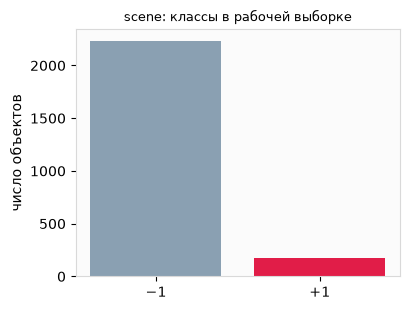

In [ ]:
## Загружаем датасет и выводим по нему информацию кол-во строк, признаков, кол-во объектов в классах 
# и рисуем диаграмму отношения классов -1 и +1
DATASET_NAME = "scene"
SUBSAMPLE = None

loaded = fetch_datasets(filter_data=(DATASET_NAME,))[DATASET_NAME]
X_all = np.asarray(loaded.data, dtype=float)
y_all = np.asarray(loaded.target, dtype=int)
n_maj, n_min = class_counts(y_all)
print(f"Полный набор {DATASET_NAME}: {X_all.shape[0]} объектов, {X_all.shape[1]} признаков")
print(f"Класс −1: {n_maj}, класс +1: {n_min}, отношение {ratio_text(y_all)}")
print("Метка класса приходит из столбца Target: fetch_datasets уже отделяет её от признаков.")

if SUBSAMPLE is not None and len(y_all) > SUBSAMPLE:
    picked, _ = train_test_split(
        np.arange(len(y_all)), train_size=SUBSAMPLE, random_state=SEED, stratify=y_all,
    )
    X, y = X_all[picked], y_all[picked]
    print(
        f"Рабочая выборка: стратифицированные {len(y)} объектов. "
        "Полный protein_homo после SMOTE раздувается почти вдвое, "
        "а t-SNE и повторная кросс-валидация SVM на сотнях тысяч строк здесь не заканчиваются. "
        f"Доля классов сохранена: {ratio_text(y)}."
    )
else:
    X, y = X_all, y_all
    print(f"Рабочая выборка совпадает с полным набором: {X.shape[0]} объектов, {X.shape[1]} признаков.")

n_maj, n_min = class_counts(y)
fig, ax = plt.subplots(figsize=(4.2, 3.2))
ax.bar(["−1", "+1"], [n_maj, n_min], color=[MAIN_COLOR, RARE_COLOR])
ax.set_ylabel("число объектов")
ax.set_title(f"{DATASET_NAME}: классы в рабочей выборке")
fig.tight_layout()
plt.show()


## Разбиение


In [ ]:
# Одно стратифицированное разбиение по заданию: test_size=0.3, random_state=42, stratify=y.
# Сэмплинг дальше применяется только к обучающей части. Тест остаётся с исходным перекосом:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y,
)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
X_all_s = scaler.transform(X)

print(f"Обучающая: {len(y_train)} объектов, {ratio_text(y_train)}")
print(f"Тестовая:  {len(y_test)} объектов, {ratio_text(y_test)}")
print(f"Кросс-валидация: RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state={SEED})")


Обучающая: 1684 объектов, 12.6 : 1
Тестовая:  723 объектов, 12.6 : 1
Кросс-валидация: RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)


## Пять алгоритмов сэмплинга

- **SMOTE** достраивает редкий класс точками на отрезках между объектом и его соседями.
- **Borderline-SMOTE1** делает то же самое, но только для объектов редкого класса, которые стоят на границе с большинством.
- **Instance Hardness Threshold** учит вспомогательную модель и выбрасывает объекты большинства, которые она и так узнаёт уверенно. Редкий класс не трогает.
- **SMOTE+IHT** сначала достраивает редкий класс, затем прореживает большинство по жесткости объектов.
- **SMOTETomek** после SMOTE удаляет пары Томека: ближайших соседей из разных классов, которые сидят друг у друга на границе.

In [ ]:
# Пять алгоритмов сэмплинга
SAMPLERS = {
    "без сэмплинга": lambda: None,
    "SMOTE": lambda: SMOTE(random_state=SEED),
    "Borderline-SMOTE1": lambda: BorderlineSMOTE(kind="borderline-1", random_state=SEED),
    "IHT": lambda: InstanceHardnessThreshold(random_state=SEED, n_jobs=1),
    "SMOTE+IHT": lambda: [
        ("smote", SMOTE(random_state=SEED)),
        ("iht", InstanceHardnessThreshold(random_state=SEED, n_jobs=1)),
    ],
    "SMOTETomek": lambda: SMOTETomek(random_state=SEED),
}


без сэмплинга: −1=1560, +1=124, 0.0 с


SMOTE: −1=1560, +1=1560, 0.1 с
Borderline-SMOTE1: −1=1560, +1=1560, 0.0 с


IHT: −1=144, +1=124, 6.8 с


SMOTE+IHT: −1=1560, +1=1560, 17.8 с
SMOTETomek: −1=1560, +1=1560, 0.1 с


,−1,+1,всего,отношение,секунды,ошибка
сэмплинг,,,,,,
без сэмплинга,1560,124,1684,12.6 : 1,0.00,
SMOTE,1560,1560,3120,1.0 : 1,0.06,
Borderline-SMOTE1,1560,1560,3120,1.0 : 1,0.01,
IHT,144,124,268,1.2 : 1,6.81,
SMOTE+IHT,1560,1560,3120,1.0 : 1,17.82,
SMOTETomek,1560,1560,3120,1.0 : 1,0.08,


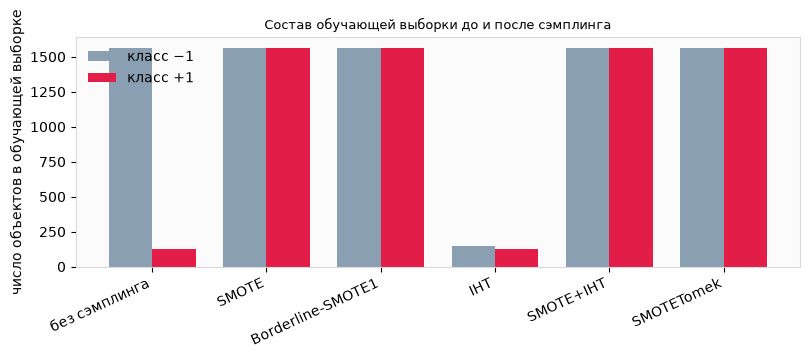

In [ ]:
## Прогоняем каждый алгоритм сэмплинга по выбрке и смотри как изменился состав классов
count_rows = []
balanced_train = {}
for sampler_name, factory in SAMPLERS.items():
    started = time.time()
    try:
        X_res, y_res = apply_sampler(factory(), X_train_s, y_train)
        error = ""
    except Exception as exc:
        X_res, y_res = None, None
        error = f"{type(exc).__name__}: {exc}"
    seconds = time.time() - started
    if error:
        count_rows.append({
            "сэмплинг": sampler_name,
            "−1": np.nan,
            "+1": np.nan,
            "всего": np.nan,
            "отношение": "—",
            "секунды": round(seconds, 2),
            "ошибка": error,
        })
        print(f"{sampler_name}: {error}")
        continue
    n_maj, n_min = class_counts(y_res)
    balanced_train[sampler_name] = (X_res, y_res)
    count_rows.append({
        "сэмплинг": sampler_name,
        "−1": n_maj,
        "+1": n_min,
        "всего": int(len(y_res)),
        "отношение": ratio_text(y_res),
        "секунды": round(seconds, 2),
        "ошибка": "",
    })
    print(f"{sampler_name}: −1={n_maj}, +1={n_min}, {seconds:.1f} с")

count_table = pd.DataFrame(count_rows).set_index("сэмплинг")
display(count_table)

plot_counts = count_table.dropna(subset=["−1"])
fig, ax = plt.subplots(figsize=(8.2, 3.6))
x = np.arange(len(plot_counts))
width = 0.38
ax.bar(x - width / 2, plot_counts["−1"], width, label="класс −1", color=MAIN_COLOR)
ax.bar(x + width / 2, plot_counts["+1"], width, label="класс +1", color=RARE_COLOR)
ax.set_xticks(x, plot_counts.index, rotation=25, ha="right")
ax.set_ylabel("число объектов в обучающей выборке")
ax.set_title("Состав обучающей выборки до и после сэмплинга")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## Вложения исходного и сбалансированных наборов

Четыре метода: t-SNE, UMAP, TriMap, PaCMAP. У каждого три сочетания параметров.
t-SNE меняет `perplexity`, UMAP — число соседей и `min_dist`, TriMap — число близких и далёких ориентиров, PaCMAP — число соседей и долю средних и дальних точек `MN_ratio` / `FP_ratio`.

Класс −1 рисуется кругом, класс +1 треугольником.
Исходное облако — вся рабочая выборка в масштабе обучающего `StandardScaler`.
Сбалансированные облака — обучающая выборка после соответствующего алгоритма: именно её видит классификатор.
Если после SMOTE точек больше 2500, на рисунок берётся стратифицированная подвыборка, в подписи указано сколько.
Координаты зависят от признаков и параметров метода, не от того, какой классификатор потом поставит метку.



исходный набор: считаем вложения, точек на рисунке 2407


  t-SNE   | perplexity=5                     |   4.4 с | ок


  t-SNE   | perplexity=30                    |   5.9 с | ок


  t-SNE   | perplexity=50                    |   6.9 с | ок


  UMAP    | соседей 5, min_dist 0            |  16.8 с | ок


...

  TriMap  | по умолчанию                     |   1.3 с | ок


  TriMap  | inliers 12, outliers 5           |   1.5 с | ок


  PaCMAP  | соседей 5                        |   0.7 с | ок


  PaCMAP  | соседей 10                       |   0.9 с | ок


  PaCMAP  | MN=2, FP=1                       |   1.1 с | ок


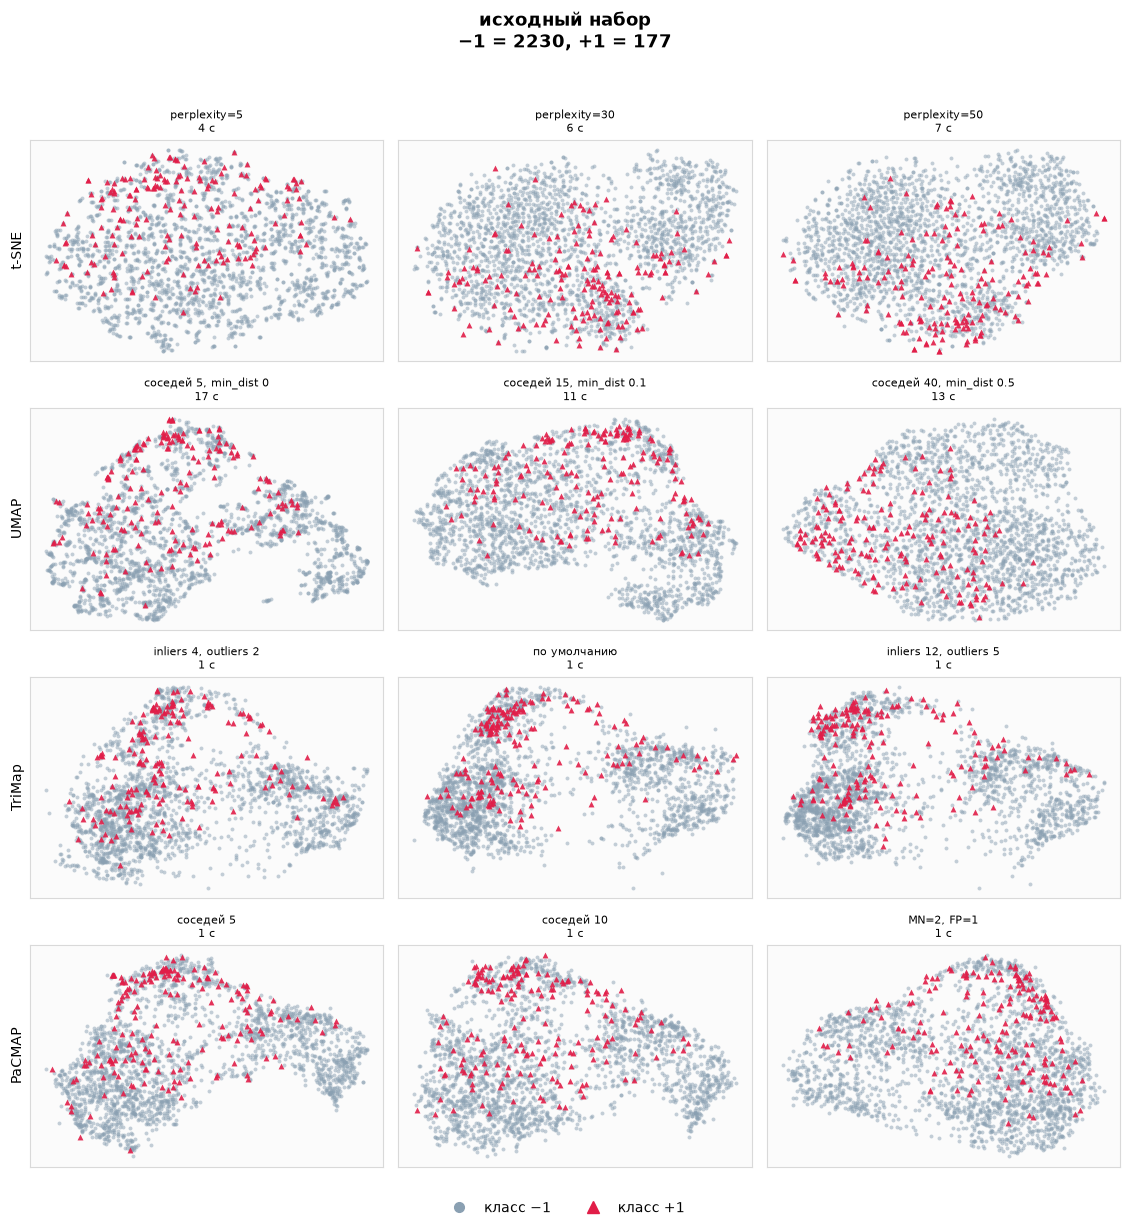


SMOTE, обучающая после сэмплинга: считаем вложения, точек на рисунке 2500


  t-SNE   | perplexity=5                     |   4.6 с | ок


  t-SNE   | perplexity=30                    |   4.9 с | ок


  t-SNE   | perplexity=50                    |   5.2 с | ок


  UMAP    | соседей 5, min_dist 0            |   9.3 с | ок


...

  TriMap  | по умолчанию                     |   1.3 с | ок


  TriMap  | inliers 12, outliers 5           |   1.5 с | ок


  PaCMAP  | соседей 5                        |   0.7 с | ок


  PaCMAP  | соседей 10                       |   0.9 с | ок


  PaCMAP  | MN=2, FP=1                       |   1.1 с | ок


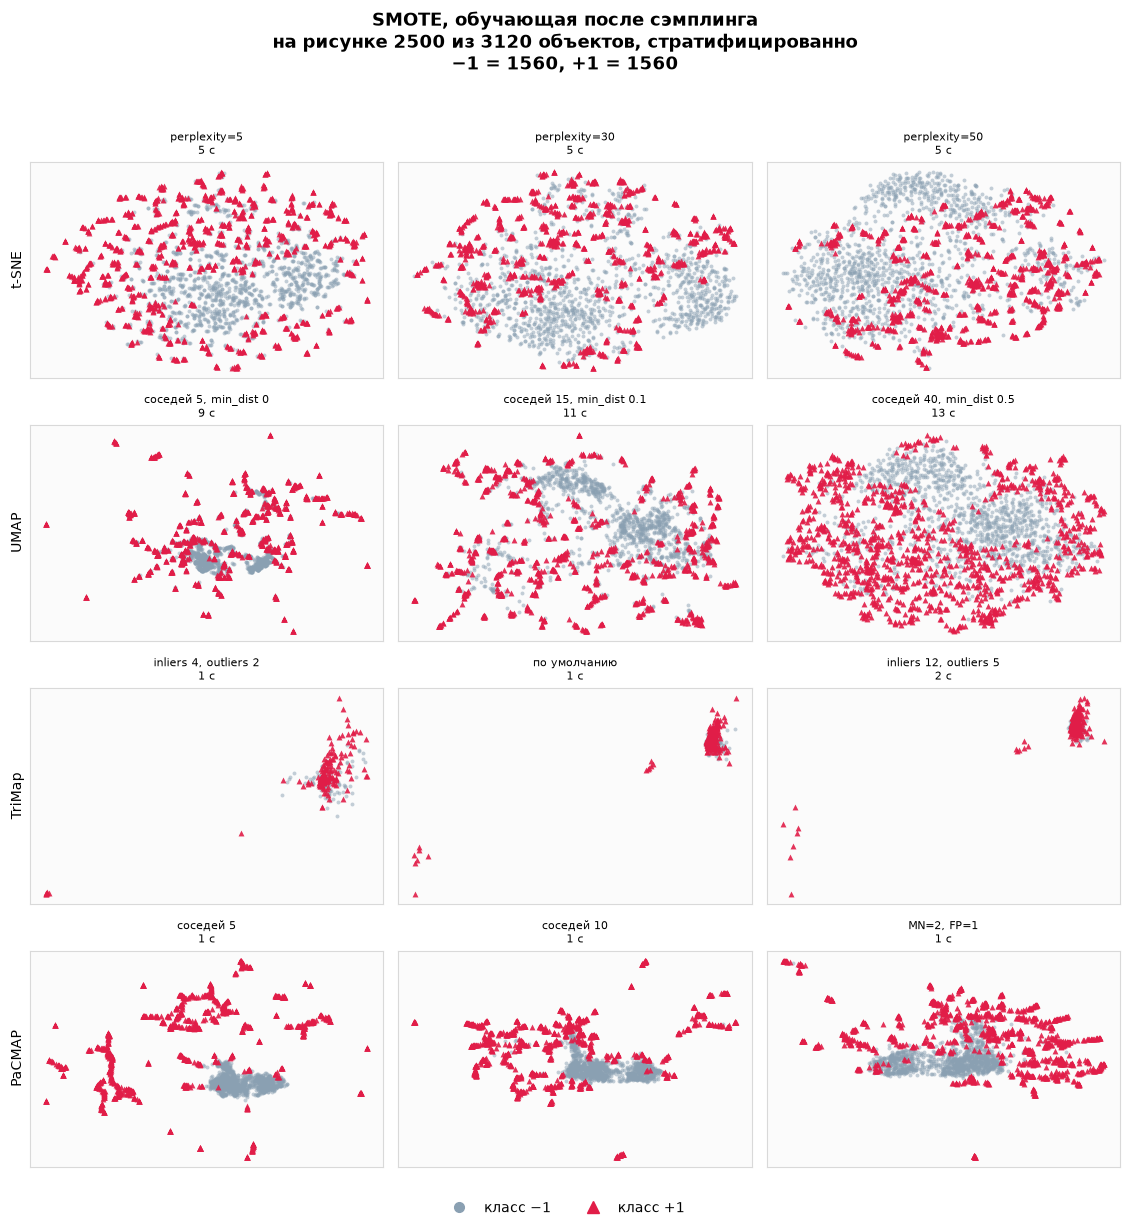


Borderline-SMOTE1, обучающая после сэмплинга: считаем вложения, точек на рисунке 2500


  t-SNE   | perplexity=5                     |   3.9 с | ок


  t-SNE   | perplexity=30                    |   5.9 с | ок


  t-SNE   | perplexity=50                    |   6.0 с | ок


  UMAP    | соседей 5, min_dist 0            |   9.5 с | ок


...

  TriMap  | по умолчанию                     |   1.3 с | ок


  TriMap  | inliers 12, outliers 5           |   1.5 с | ок


  PaCMAP  | соседей 5                        |   0.6 с | ок


  PaCMAP  | соседей 10                       |   0.9 с | ок


  PaCMAP  | MN=2, FP=1                       |   1.1 с | ок


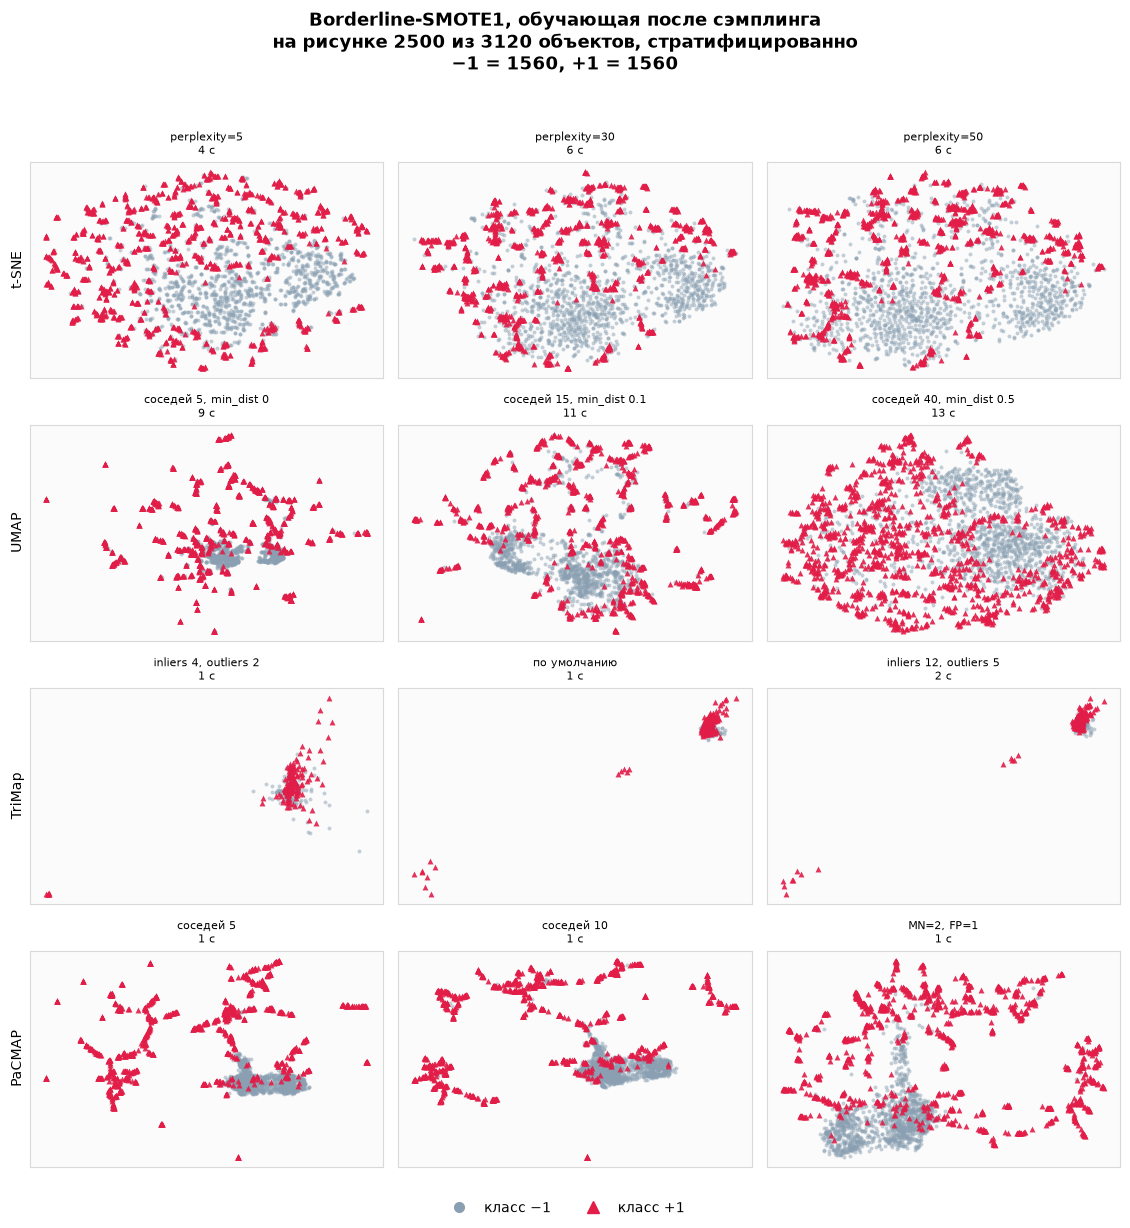


IHT, обучающая после сэмплинга: считаем вложения, точек на рисунке 268


  t-SNE   | perplexity=5                     |   0.5 с | ок


  t-SNE   | perplexity=30                    |   0.5 с | ок


  t-SNE   | perplexity=50                    |   0.6 с | ок


  UMAP    | соседей 5, min_dist 0            |   0.4 с | ок


...

  TriMap  | по умолчанию                     |   0.2 с | ок


  TriMap  | inliers 12, outliers 5           |   0.2 с | ок


  PaCMAP  | соседей 5                        |   0.3 с | ок


  PaCMAP  | соседей 10                       |   0.3 с | ок


  PaCMAP  | MN=2, FP=1                       |   0.3 с | ок


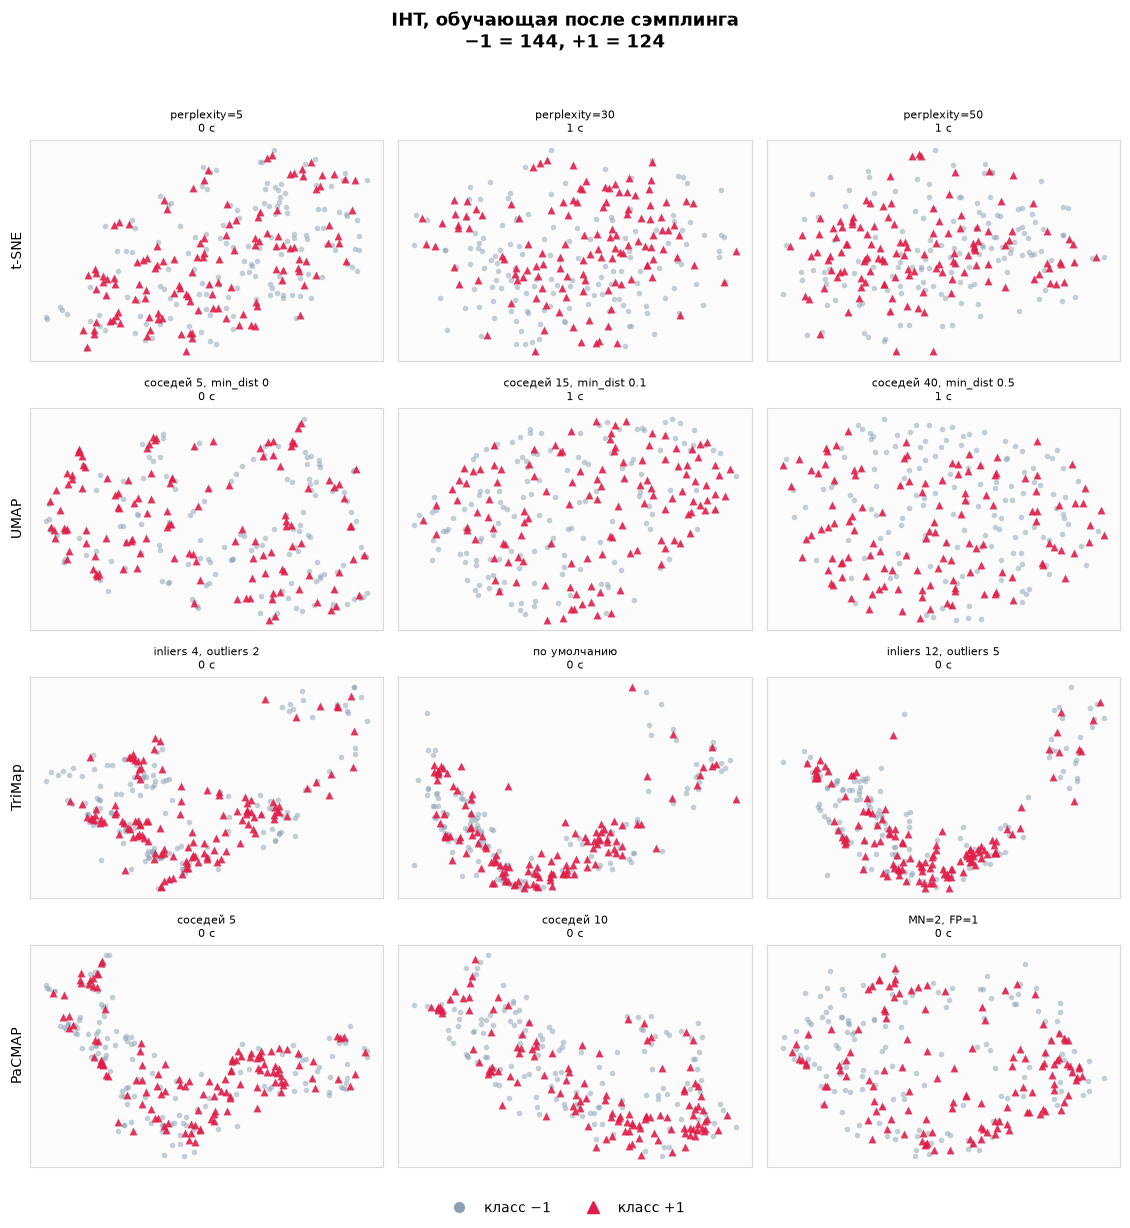


SMOTE+IHT, обучающая после сэмплинга: считаем вложения, точек на рисунке 2500


  t-SNE   | perplexity=5                     |   4.3 с | ок


  t-SNE   | perplexity=30                    |   5.0 с | ок


  t-SNE   | perplexity=50                    |   5.9 с | ок


  UMAP    | соседей 5, min_dist 0            |   9.7 с | ок


...

  TriMap  | по умолчанию                     |   1.3 с | ок


  TriMap  | inliers 12, outliers 5           |   1.5 с | ок


  PaCMAP  | соседей 5                        |   0.7 с | ок


  PaCMAP  | соседей 10                       |   0.9 с | ок


  PaCMAP  | MN=2, FP=1                       |   1.1 с | ок


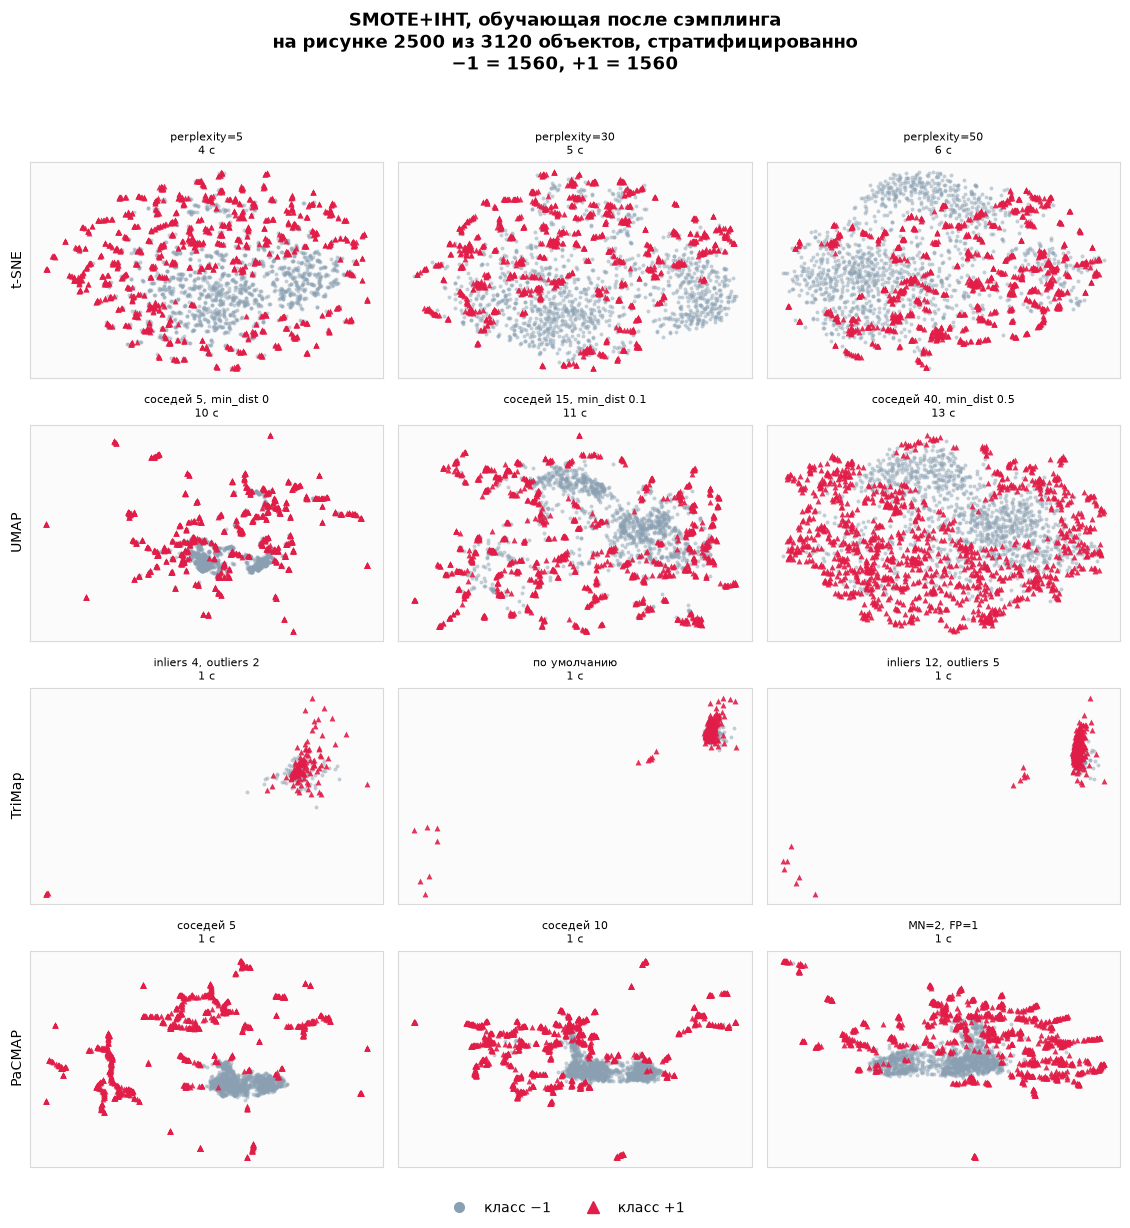


SMOTETomek, обучающая после сэмплинга: считаем вложения, точек на рисунке 2500


  t-SNE   | perplexity=5                     |   3.8 с | ок


  t-SNE   | perplexity=30                    |   4.7 с | ок


  t-SNE   | perplexity=50                    |   5.3 с | ок


  UMAP    | соседей 5, min_dist 0            |   9.2 с | ок


...

  TriMap  | по умолчанию                     |   1.4 с | ок


  TriMap  | inliers 12, outliers 5           |   1.5 с | ок


  PaCMAP  | соседей 5                        |   0.6 с | ок


  PaCMAP  | соседей 10                       |   0.9 с | ок


  PaCMAP  | MN=2, FP=1                       |   1.1 с | ок


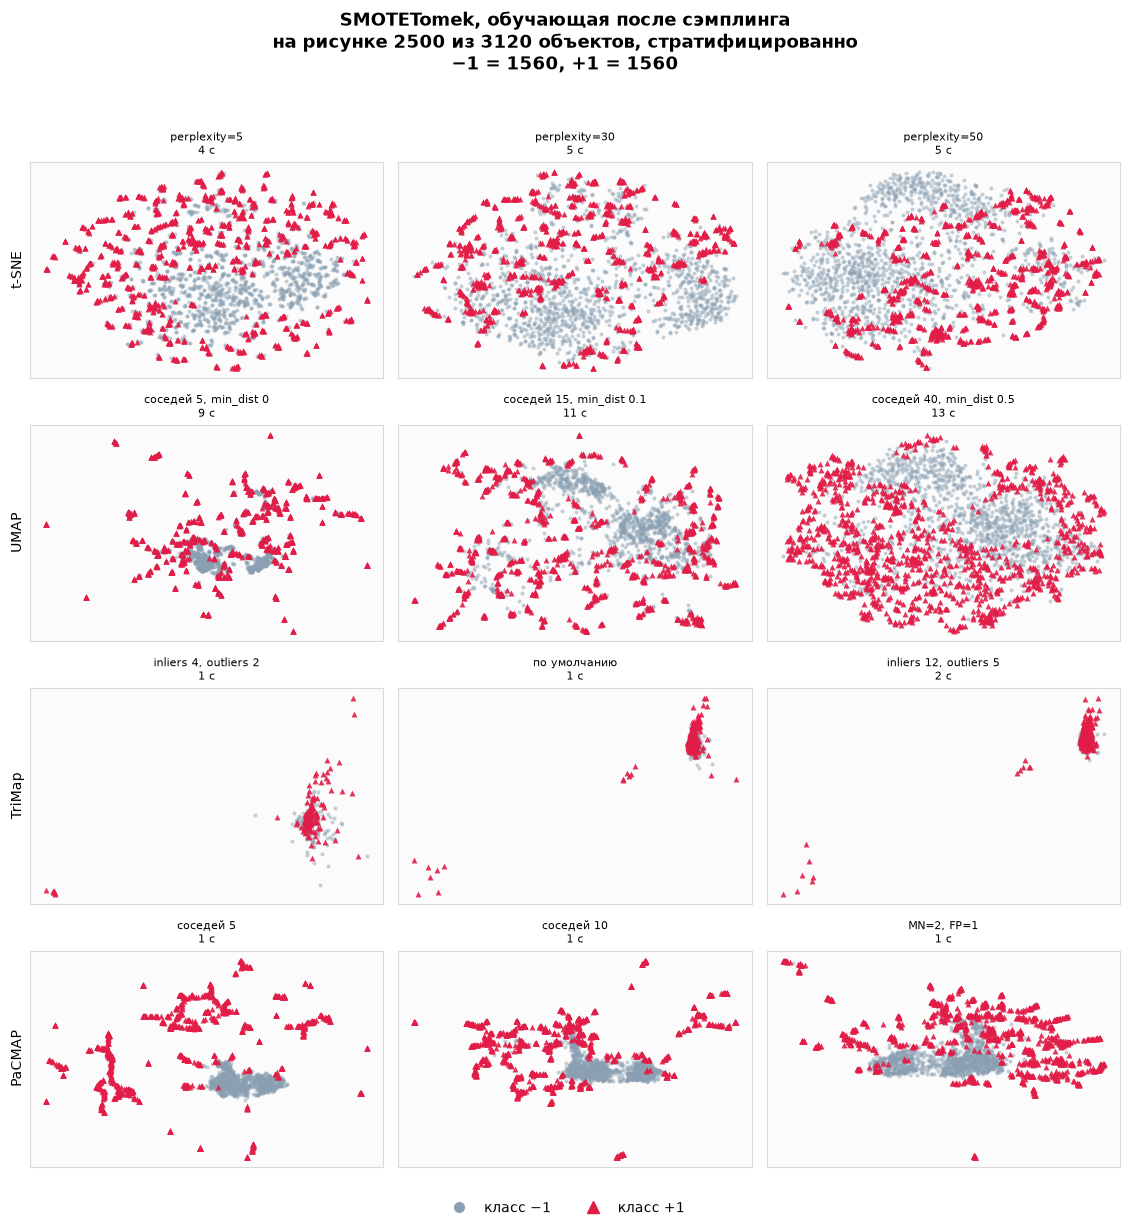

In [ ]:
## рисуем каждую успешно сбалансированную выборку с применением 
# соответствующего метода сэмплинга и для каждого строится облако с применением
# снижения размерности с разными параметрами 
clouds = [("исходный набор", X_all_s, y)]
for sampler_name, _factory in list(SAMPLERS.items())[1:]:
    if sampler_name not in balanced_train:
        print(f"{sampler_name} пропущен: сэмплинг не собрал выборку")
        continue
    clouds.append((f"{sampler_name}, обучающая после сэмплинга", *balanced_train[sampler_name]))

cloud_embeddings = {}
for title, matrix, labels in clouds:
    matrix_plot, labels_plot = take_for_plot(matrix, labels)
    caption = title
    if len(labels_plot) < len(labels):
        caption += f"\nна рисунке {len(labels_plot)} из {len(labels)} объектов, стратифицированно"
    caption += f"\n−1 = {class_counts(labels)[0]}, +1 = {class_counts(labels)[1]}"
    print(f"\n{title}: считаем вложения, точек на рисунке {len(labels_plot)}")
    stored = compute_grid(matrix_plot, labels_plot)
    cloud_embeddings[title] = (stored, labels_plot)
    show_embedding_grid(caption, stored, labels_plot)


## Классификаторы на кросс-валидации

kNN с пятью соседями, SVM с RBF (`C=1`, `gamma='scale'`), лес из 100 деревьев.
В каждом фолде конвейер заново учит масштаб, заново запускает сэмплинг и только потом учит классификатор.
В таблице среднее и разброс по 15 разбиениям. Столбцы — Balanced Accuracy и F1, подписи на оси — классификатор и алгоритм сэмплинга.


kNN  | без сэмплинга          | BA 0.526±0.017 | F1 0.100±0.056 | 5 с


SVM  | без сэмплинга          | BA 0.504±0.006 | F1 0.015±0.024 | 2 с


RF   | без сэмплинга          | BA 0.519±0.016 | F1 0.073±0.059 | 6 с


kNN  | SMOTE                  | BA 0.688±0.033 | F1 0.232±0.017 | 1 с


SVM  | SMOTE                  | BA 0.596±0.034 | F1 0.264±0.067 | 5 с


...

RF   | SMOTE+IHT              | BA 0.555±0.030 | F1 0.182±0.071 | 79 с


kNN  | SMOTETomek             | BA 0.688±0.033 | F1 0.232±0.017 | 3 с


SVM  | SMOTETomek             | BA 0.596±0.034 | F1 0.264±0.067 | 6 с


RF   | SMOTETomek             | BA 0.555±0.029 | F1 0.179±0.069 | 19 с


,классификатор,сэмплинг,Balanced Accuracy,BA std,F1-score,F1 std,секунды,ошибка
0,kNN,без сэмплинга,0.5259,0.0167,0.1002,0.0562,4.8,
1,SVM,без сэмплинга,0.5038,0.0063,0.0147,0.0244,1.6,
2,RF,без сэмплинга,0.5191,0.0162,0.0731,0.0593,6.3,
3,kNN,SMOTE,0.6882,0.0325,0.2318,0.0174,1.0,
4,SVM,SMOTE,0.5961,0.0344,0.2643,0.0669,5.4,
5,RF,SMOTE,0.5567,0.0275,0.1856,0.0652,17.2,
6,kNN,Borderline-SMOTE1,0.6858,0.0453,0.2439,0.0277,0.4,
7,SVM,Borderline-SMOTE1,0.5870,0.0307,0.2577,0.0689,3.9,
8,RF,Borderline-SMOTE1,0.5622,0.0262,0.2042,0.0673,15.3,
9,kNN,IHT,0.4674,0.0285,0.1266,0.0084,21.1,


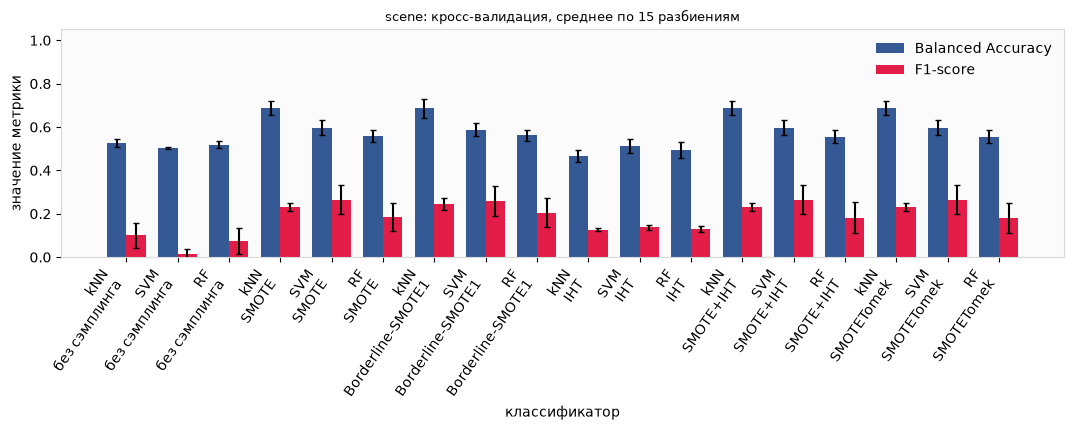

In [ ]:
## Оцениваем каждую связку классификатор-сэмплинг по различным подвыборкам(кросс-валидация)
## И рисуем столбчатую диаграмму качества 
cv_rows = []
for sampler_name, factory in SAMPLERS.items():
    for clf_name in CLF_NAMES:
        model = make_model(factory(), clf_factory(clf_name))
        started = time.time()
        try:
            scores = cross_validate(
                model, X, y, cv=CV, scoring=SCORING, n_jobs=-1, error_score="raise",
            )
            error = ""
            ba = scores["test_Balanced Accuracy"]
            f1v = scores["test_F1-score"]
            ba_mean, ba_std = float(ba.mean()), float(ba.std())
            f1_mean, f1_std = float(f1v.mean()), float(f1v.std())
        except Exception as exc:
            error = f"{type(exc).__name__}: {exc}"
            ba_mean = ba_std = f1_mean = f1_std = np.nan
        seconds = time.time() - started
        cv_rows.append({
            "классификатор": clf_name,
            "сэмплинг": sampler_name,
            "Balanced Accuracy": ba_mean,
            "BA std": ba_std,
            "F1-score": f1_mean,
            "F1 std": f1_std,
            "секунды": round(seconds, 1),
            "ошибка": error,
        })
        if error:
            print(f"{clf_name} | {sampler_name}: {error}")
        else:
            print(
                f"{clf_name:<4} | {sampler_name:<22} | "
                f"BA {ba_mean:.3f}±{ba_std:.3f} | F1 {f1_mean:.3f}±{f1_std:.3f} | {seconds:.0f} с"
            )

cv_table = pd.DataFrame(cv_rows)
display(cv_table.round(4))

cv_ok = cv_table.dropna(subset=["Balanced Accuracy"]).copy()
cv_ok["название"] = cv_ok["классификатор"] + "\n" + cv_ok["сэмплинг"]
cv_plot = cv_ok.set_index("название")[["Balanced Accuracy", "F1-score", "BA std", "F1 std"]]
metric_bars(cv_plot, f"{DATASET_NAME}: кросс-валидация, среднее по 15 разбиениям")


## Отложенная выборка

То же семейство моделей на одном разбиении 70/30.
Тест общий и несбалансированный. Эта цифра отвечает на вопрос задания про одно разбиение, кросс-валидация выше — про устойчивость.


kNN  | без сэмплинга          | BA 0.554 | F1 0.190


SVM  | без сэмплинга          | BA 0.509 | F1 0.037


RF   | без сэмплинга          | BA 0.528 | F1 0.105
kNN  | SMOTE                  | BA 0.691 | F1 0.233


SVM  | SMOTE                  | BA 0.614 | F1 0.286


RF   | SMOTE                  | BA 0.579 | F1 0.241
kNN  | Borderline-SMOTE1      | BA 0.699 | F1 0.259


...

SVM  | SMOTE+IHT              | BA 0.614 | F1 0.286


RF   | SMOTE+IHT              | BA 0.571 | F1 0.225
kNN  | SMOTETomek             | BA 0.691 | F1 0.233


SVM  | SMOTETomek             | BA 0.614 | F1 0.286


RF   | SMOTETomek             | BA 0.579 | F1 0.241


,классификатор,сэмплинг,Balanced Accuracy,F1-score,секунды,ошибка
0,kNN,без сэмплинга,0.5536,0.1905,0.03,
1,SVM,без сэмплинга,0.5094,0.0370,0.24,
2,RF,без сэмплинга,0.5276,0.1053,1.76,
3,kNN,SMOTE,0.6908,0.2332,0.04,
4,SVM,SMOTE,0.6139,0.2857,0.56,
5,RF,SMOTE,0.5794,0.2410,4.80,
6,kNN,Borderline-SMOTE1,0.6986,0.2590,0.04,
7,SVM,Borderline-SMOTE1,0.6164,0.3182,0.53,
8,RF,Borderline-SMOTE1,0.5839,0.2597,4.72,
9,kNN,IHT,0.4482,0.1213,6.51,


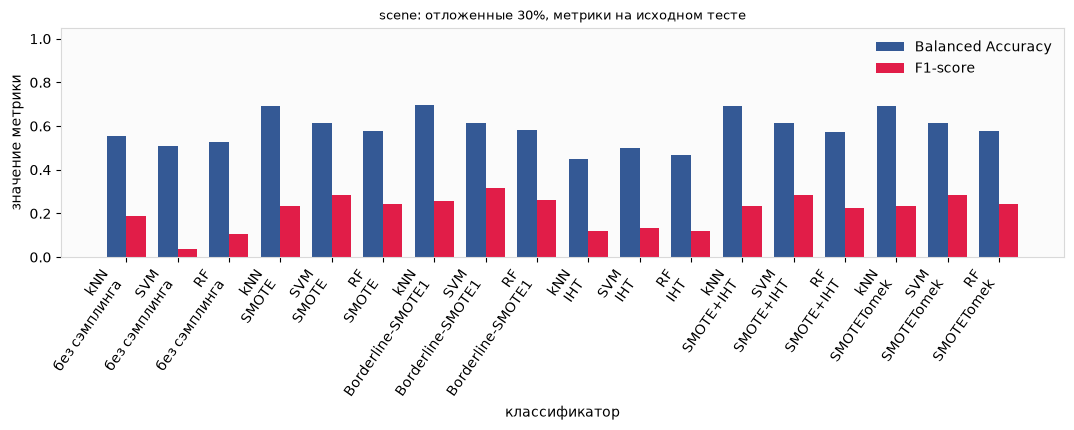

In [ ]:
## Те же модели как в предыдущей ячейке проверяем разбиение, 
# нету кросс валидации разбиваем данные в отношении train/test 70/30
## Отрисовываем результаты оценки и диаграмму оценки 
fitted = {}
hold_rows = []
for sampler_name, factory in SAMPLERS.items():
    for clf_name in CLF_NAMES:
        model = make_model(factory(), clf_factory(clf_name))
        started = time.time()
        try:
            model.fit(X_train, y_train)
            pred = model.predict(X_test)
            ba, f1v = metric_pair(y_test, pred)
            error = ""
            fitted[(clf_name, sampler_name)] = model
        except Exception as exc:
            error = f"{type(exc).__name__}: {exc}"
            ba, f1v = np.nan, np.nan
            pred = None
        hold_rows.append({
            "классификатор": clf_name,
            "сэмплинг": sampler_name,
            "Balanced Accuracy": ba,
            "F1-score": f1v,
            "секунды": round(time.time() - started, 2),
            "ошибка": error,
        })
        if error:
            print(f"{clf_name} | {sampler_name}: {error}")
        else:
            print(f"{clf_name:<4} | {sampler_name:<22} | BA {ba:.3f} | F1 {f1v:.3f}")

hold_table = pd.DataFrame(hold_rows)
display(hold_table.round(4))

hold_ok = hold_table.dropna(subset=["Balanced Accuracy"]).copy()
hold_ok["название"] = hold_ok["классификатор"] + "\n" + hold_ok["сэмплинг"]
hold_plot = hold_ok.set_index("название")[["Balanced Accuracy", "F1-score"]]
metric_bars(hold_plot, f"{DATASET_NAME}: отложенные 30%, метрики на исходном тесте")


## Истинные метки и метки классификатора

Координаты здесь считаются по тестовой выборке, один раз на метод.
Верхний ряд — известные метки, нижний — метки, которые поставил классификатор.
Столбцы — обучение без сэмплинга и пять алгоритмов. Если нижний ряд потерял красные треугольники, модель отдала редкий класс большинству.

Следом для лучшей по тесту связки показаны уже разные параметры вложения: те же точки, другая картинка близости.


Вложения тестовой выборки. Раскраска прогноза эти координаты не меняет.


  t-SNE   | perplexity=5                     |   1.0 с | ок


  t-SNE   | perplexity=30                    |   1.2 с | ок


  t-SNE   | perplexity=50                    |   1.4 с | ок


  UMAP    | соседей 5, min_dist 0            |   1.4 с | ок


...

  TriMap  | по умолчанию                     |   0.4 с | ок


  TriMap  | inliers 12, outliers 5           |   0.5 с | ок


  PaCMAP  | соседей 5                        |   0.3 с | ок


  PaCMAP  | соседей 10                       |   0.4 с | ок


  PaCMAP  | MN=2, FP=1                       |   0.5 с | ок


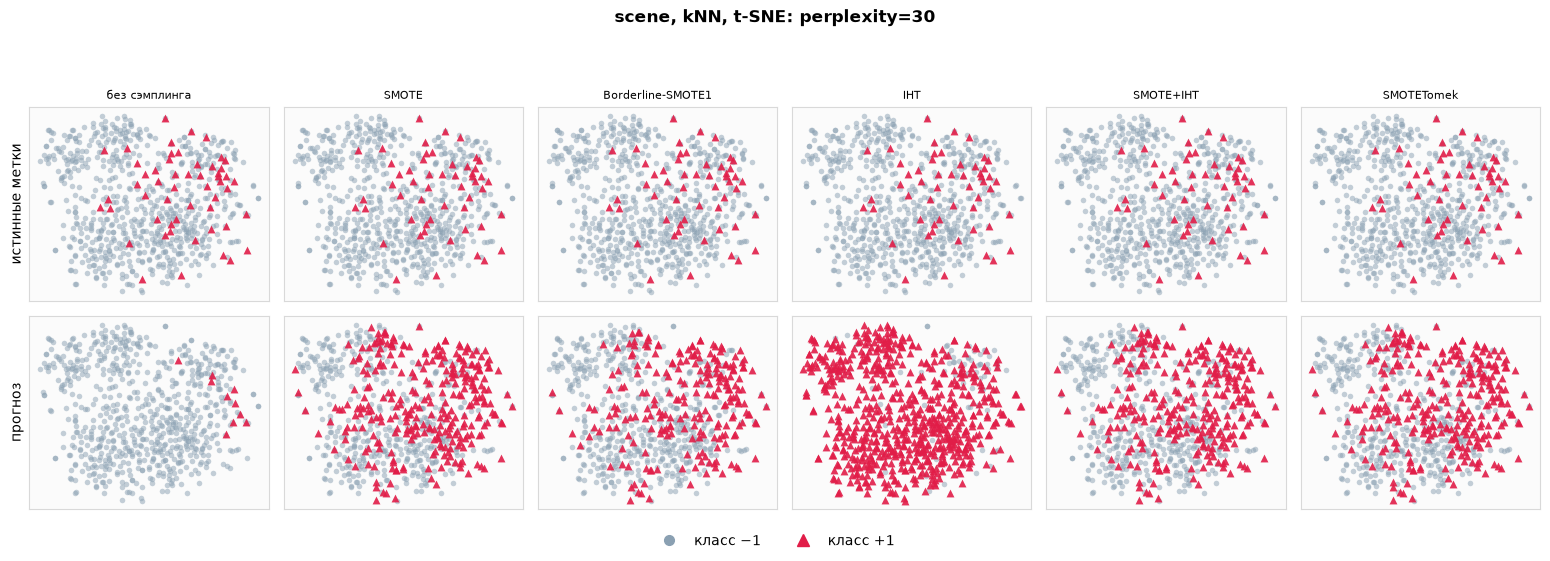

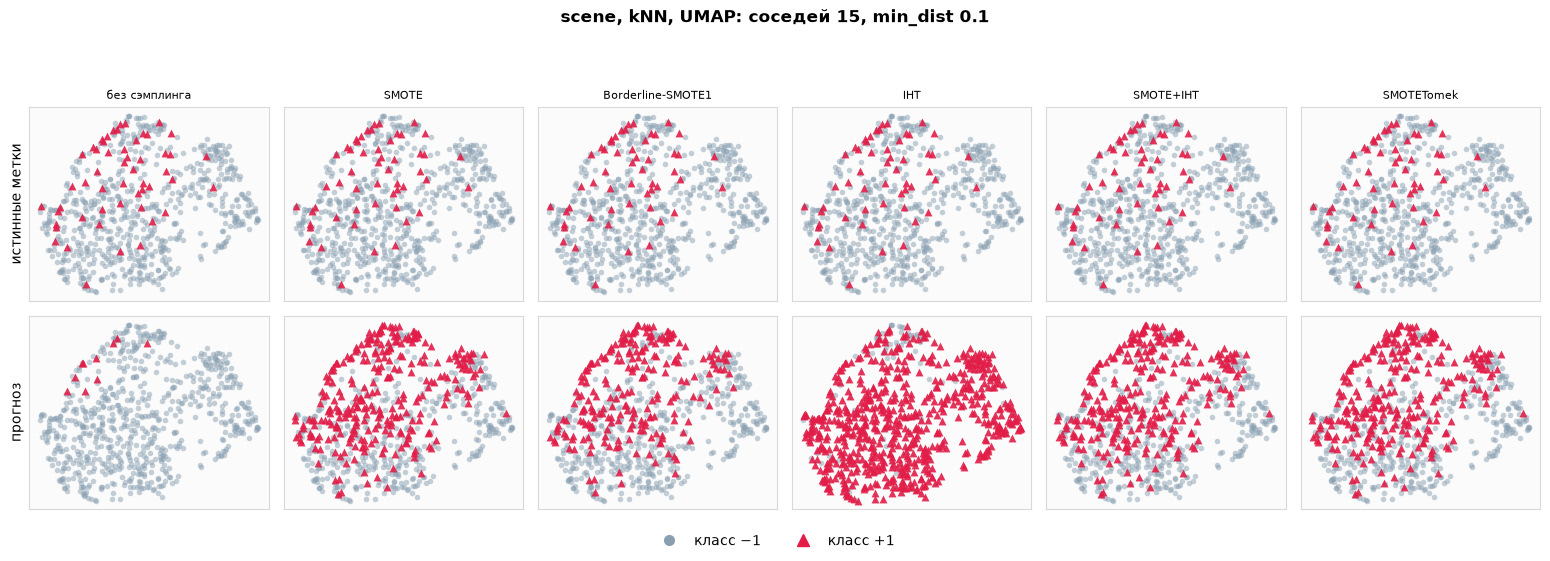

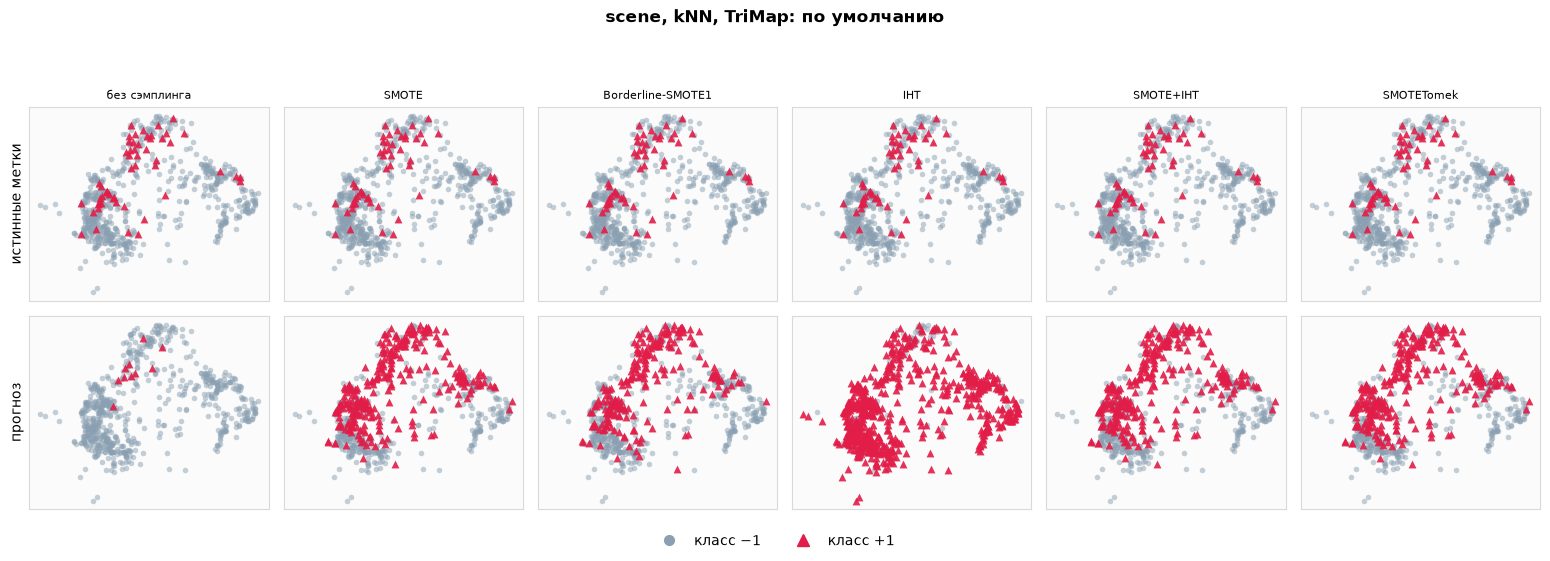

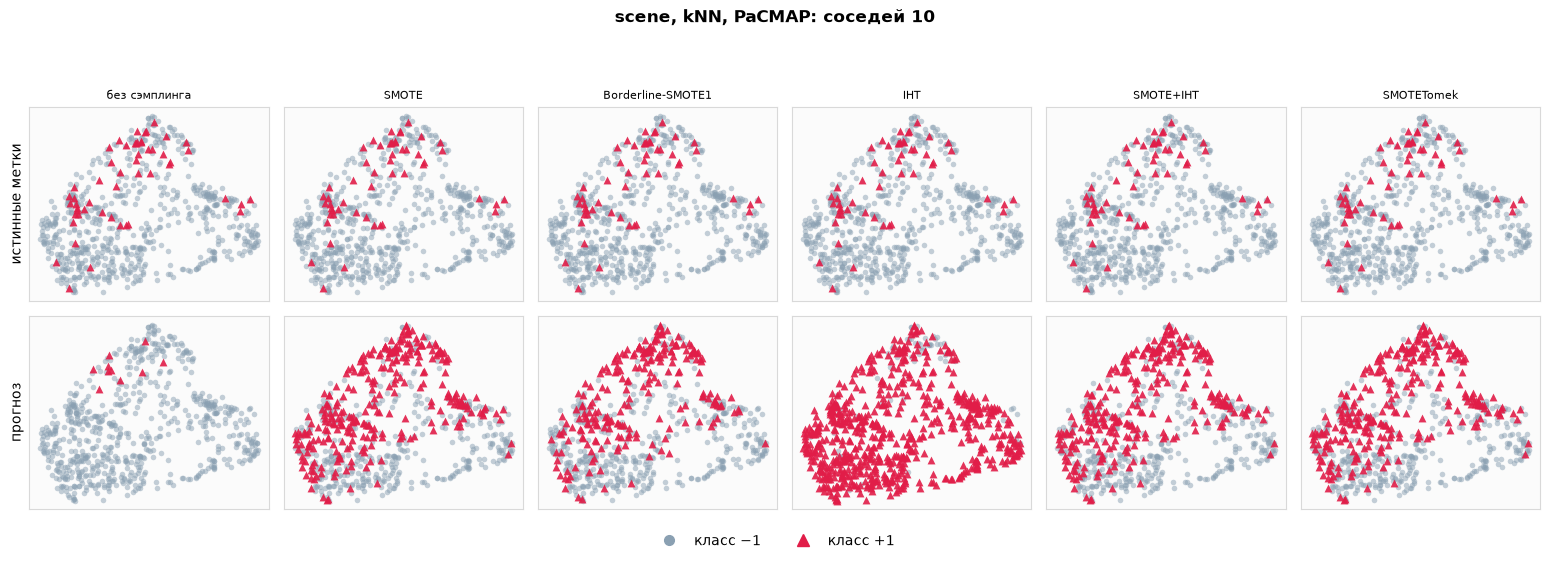

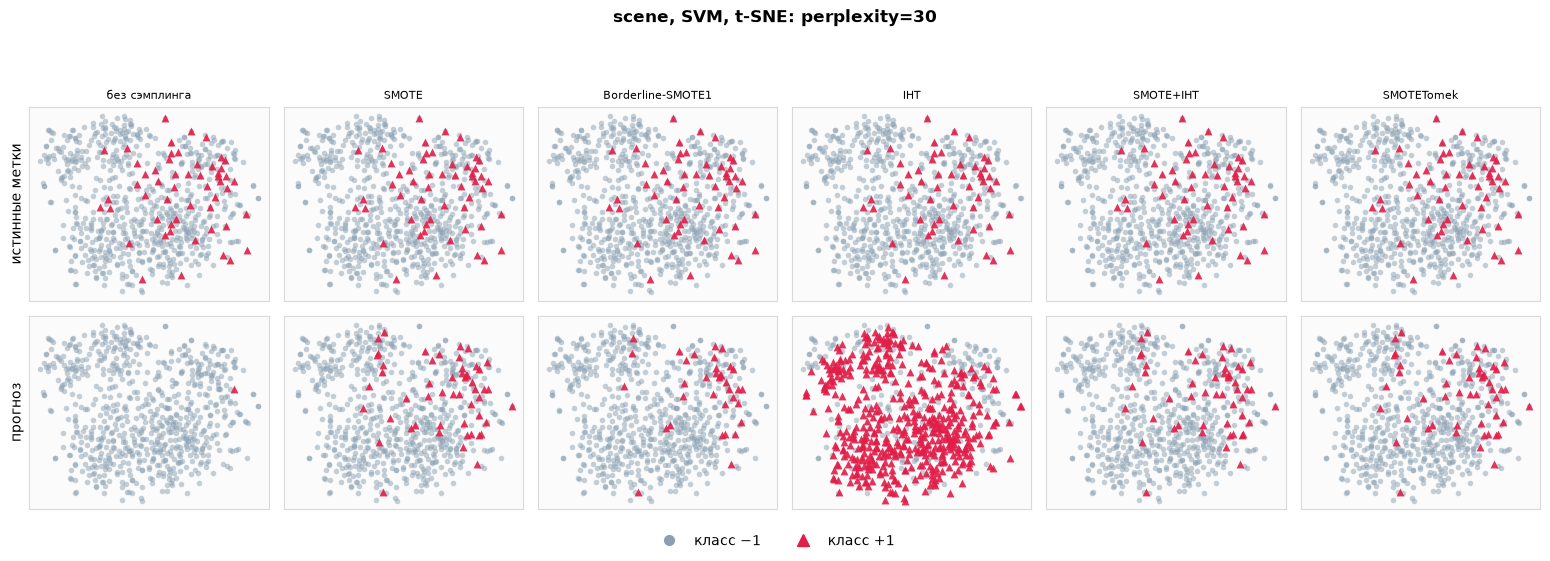

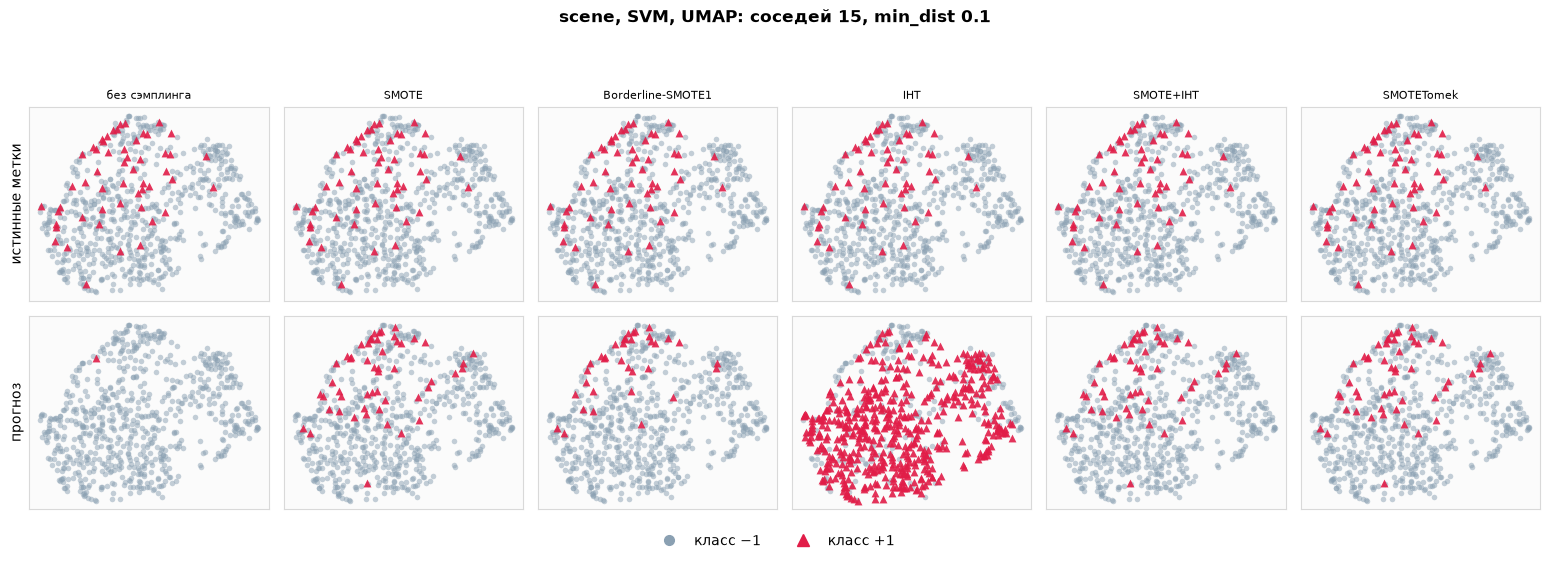

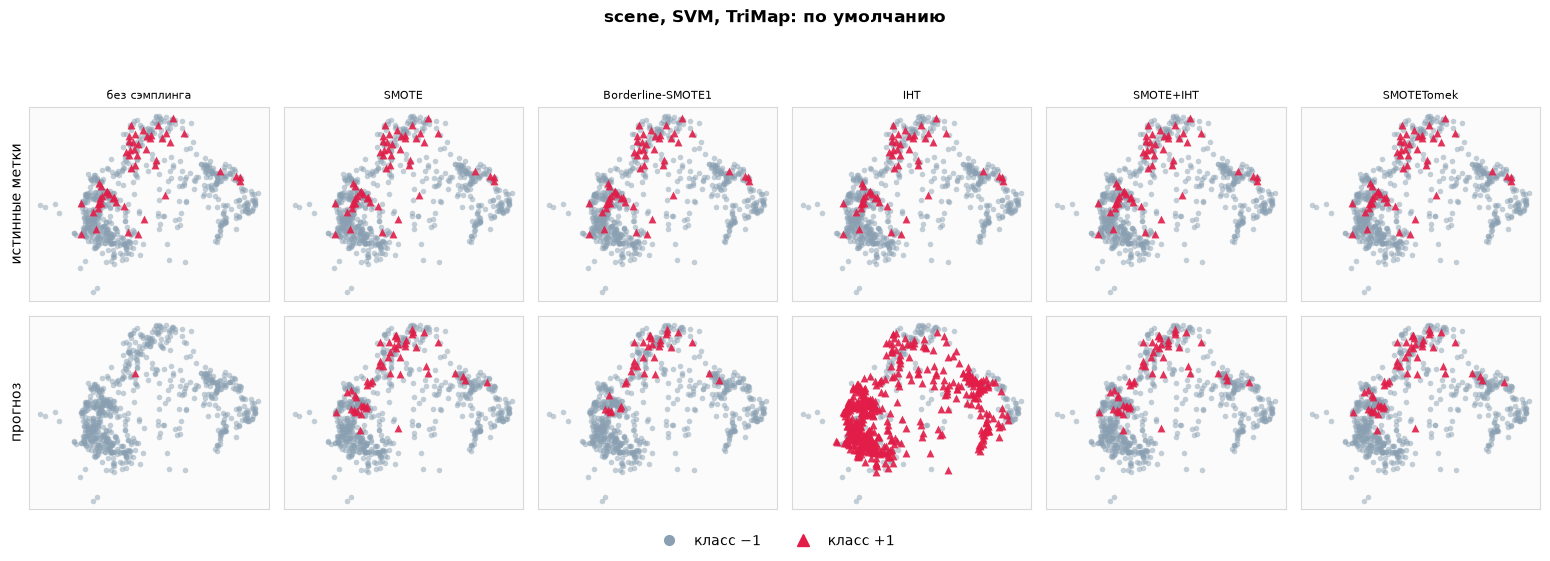

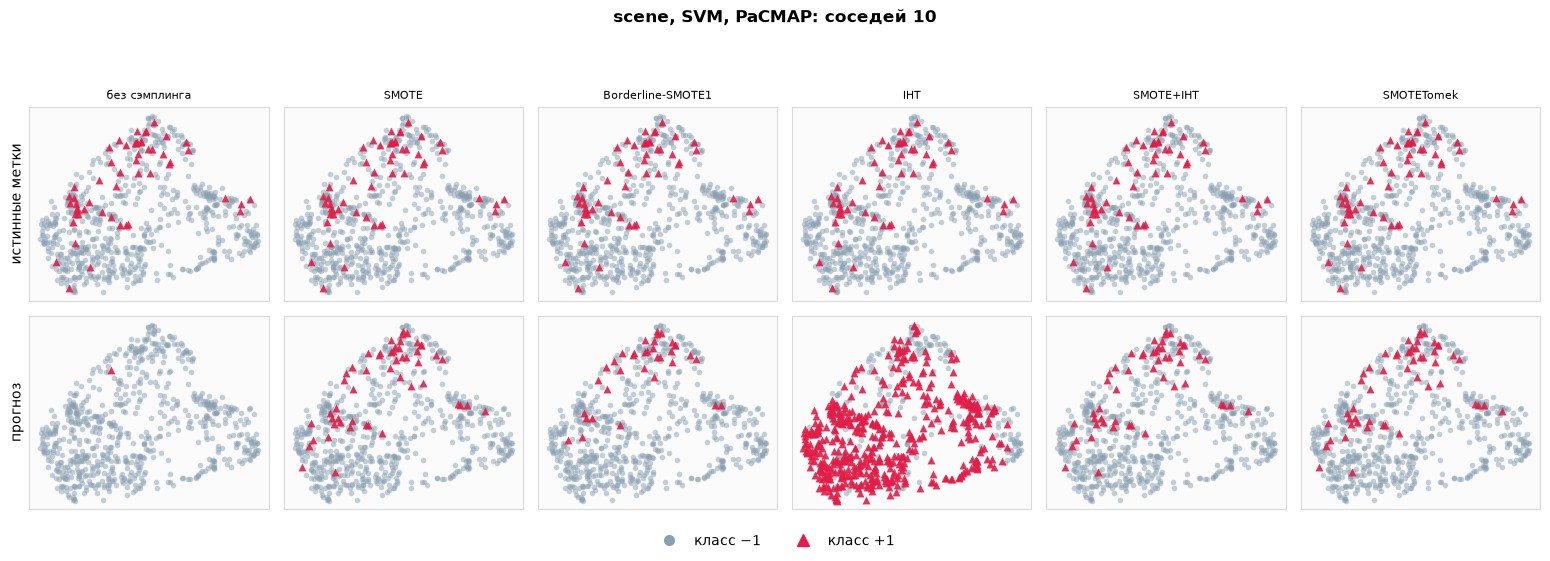

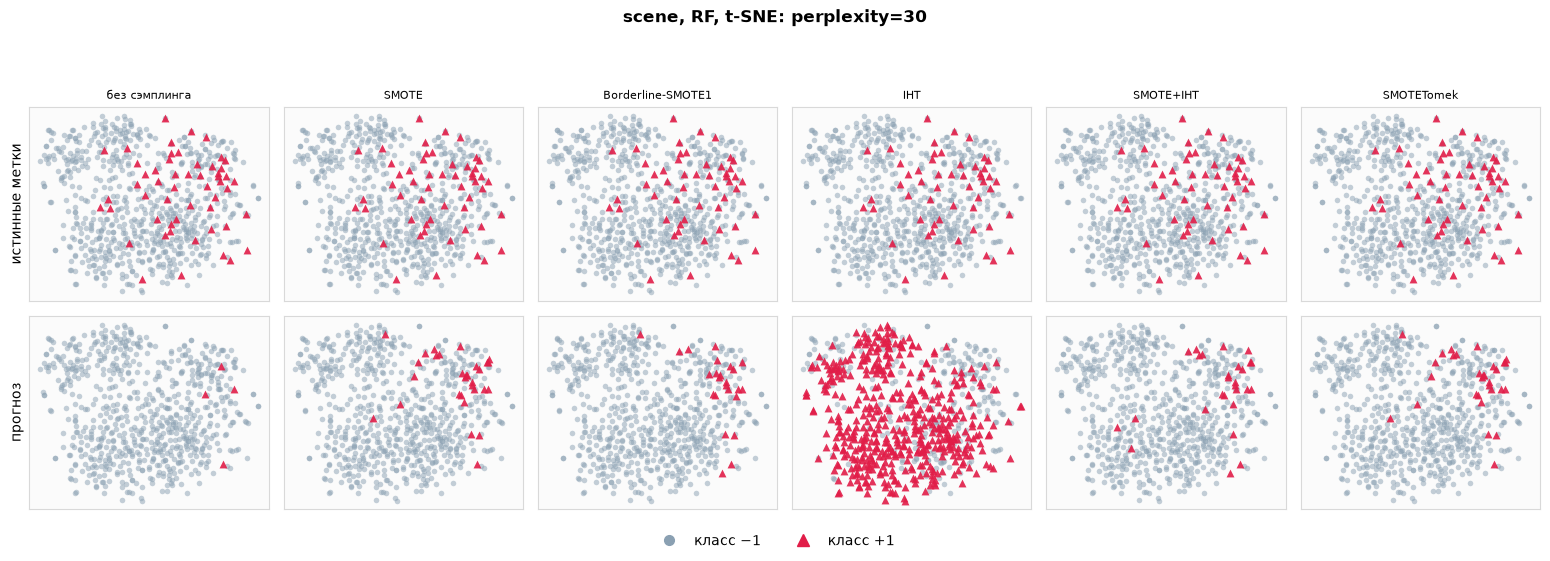

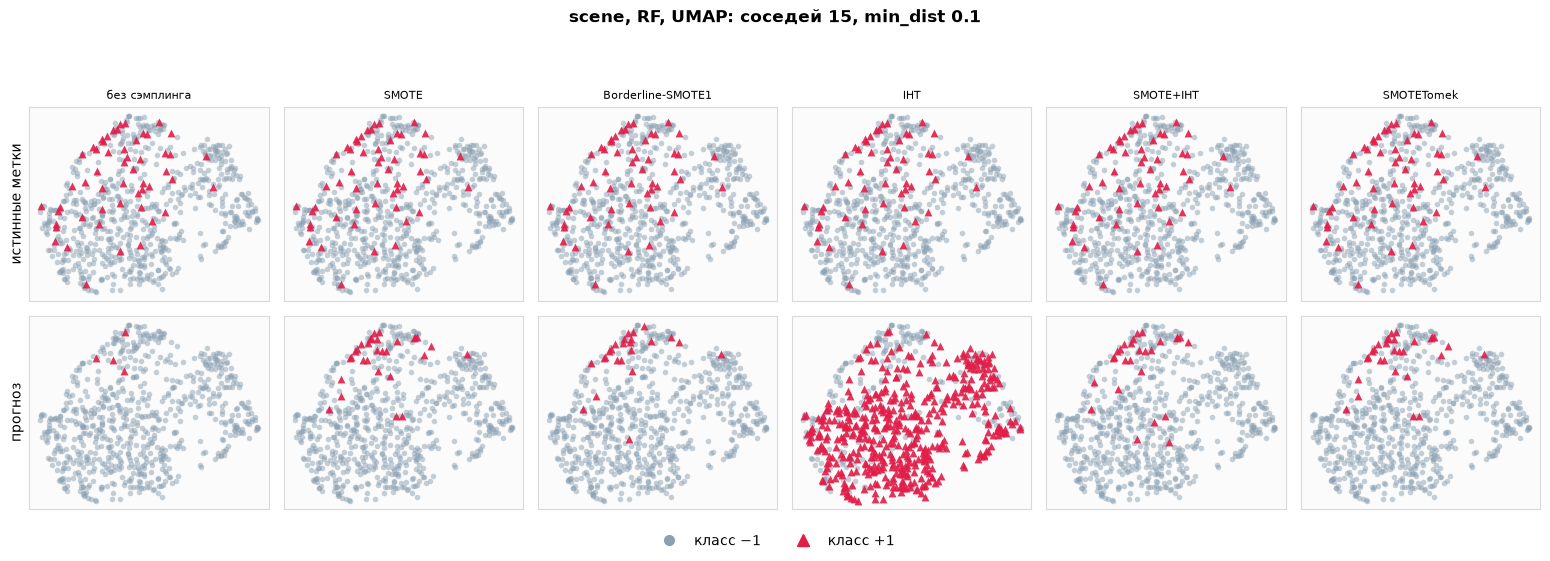

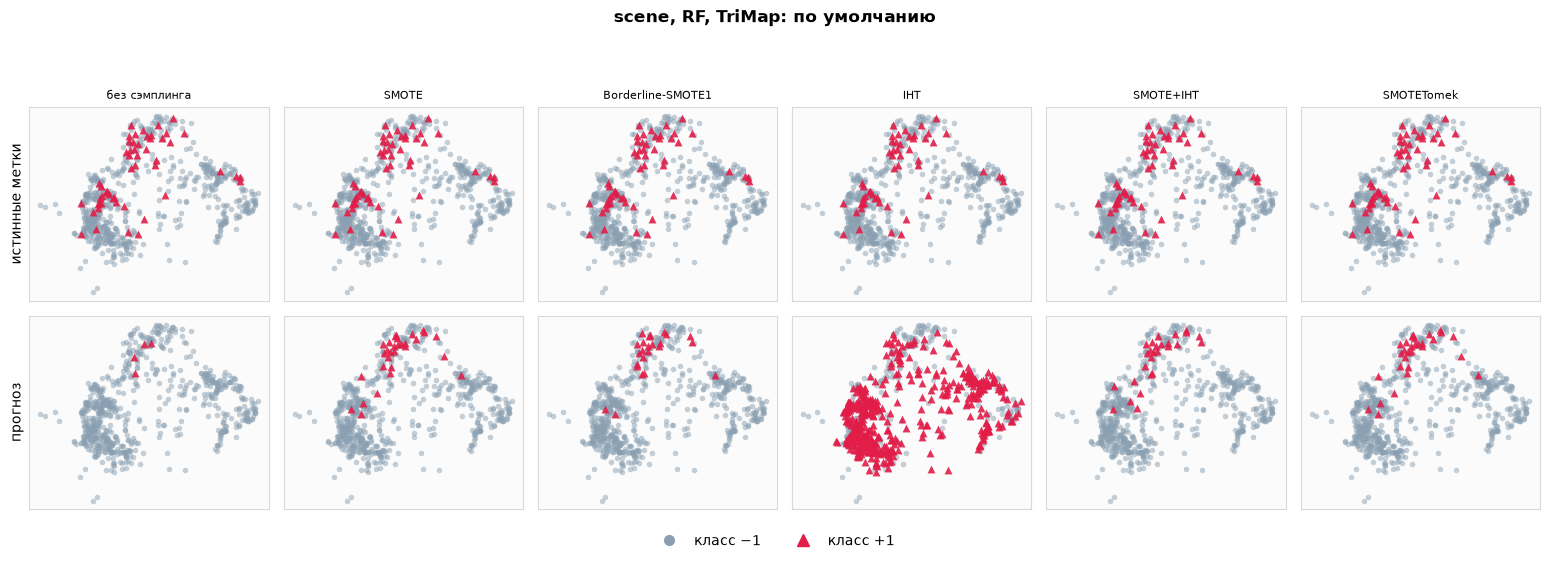

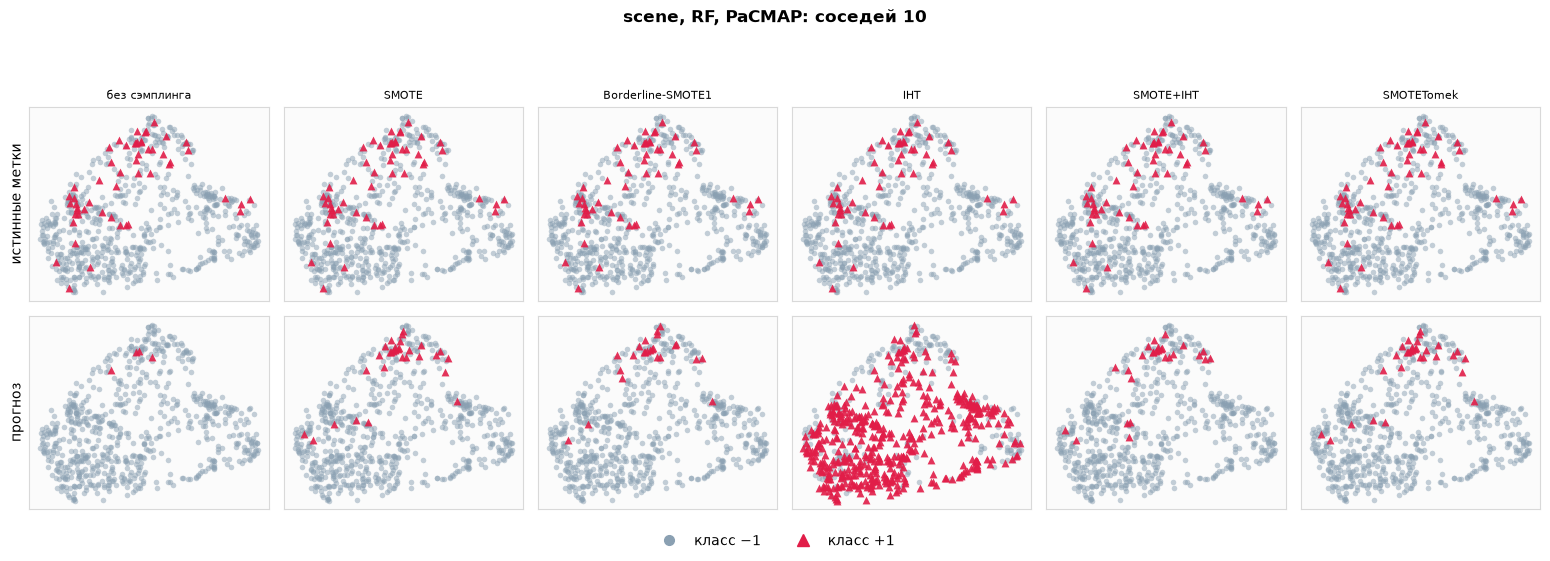

Дальше параметры вложений показаны для kNN + Borderline-SMOTE1: BA 0.699, F1 0.259.


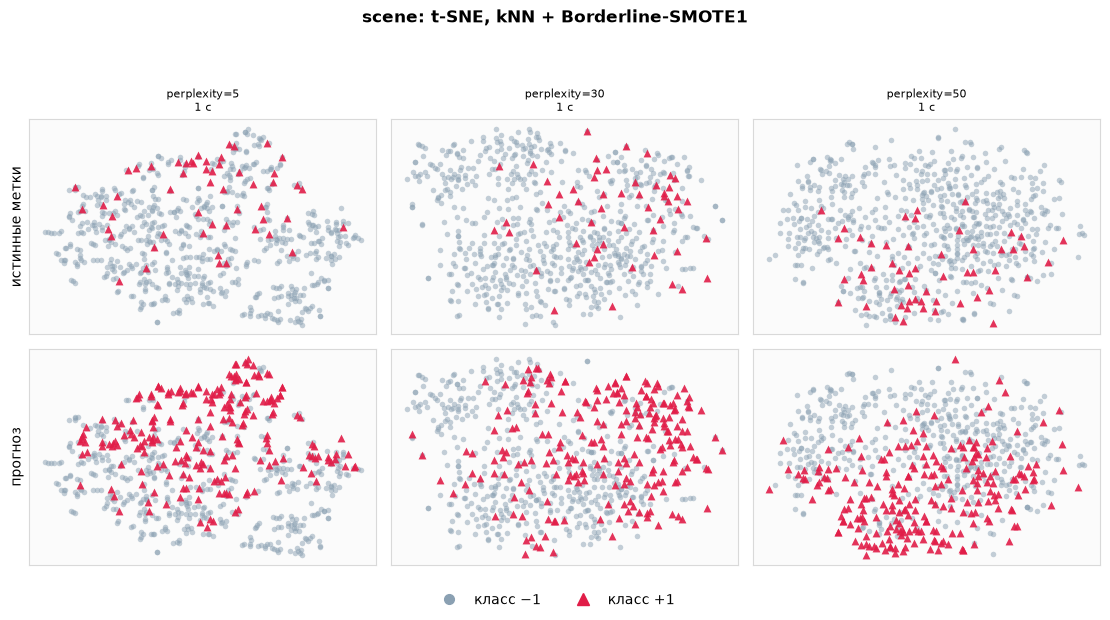

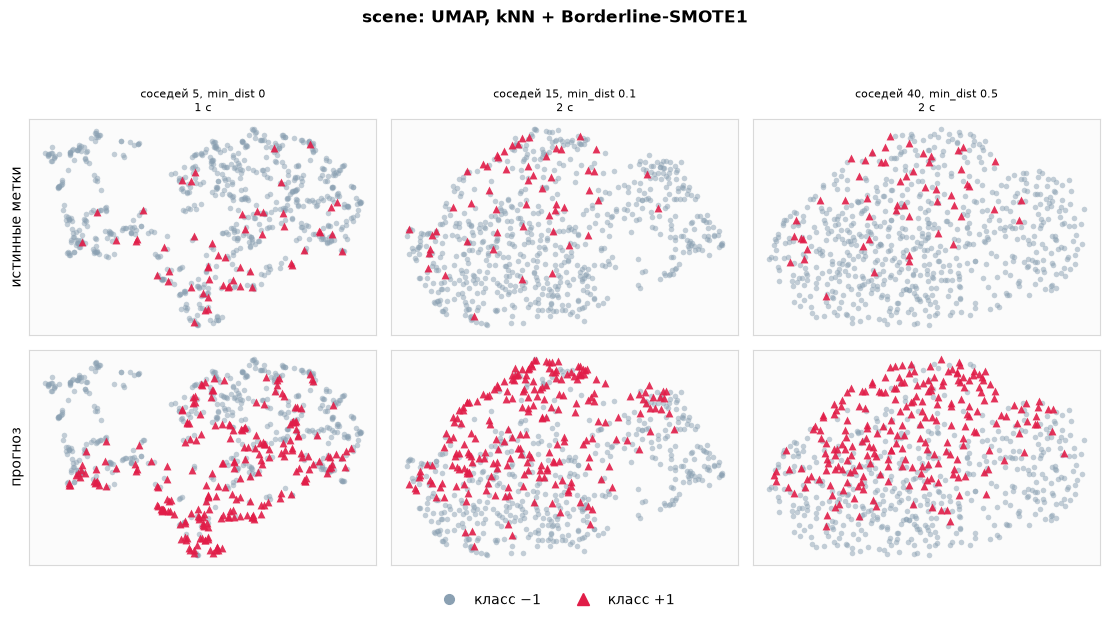

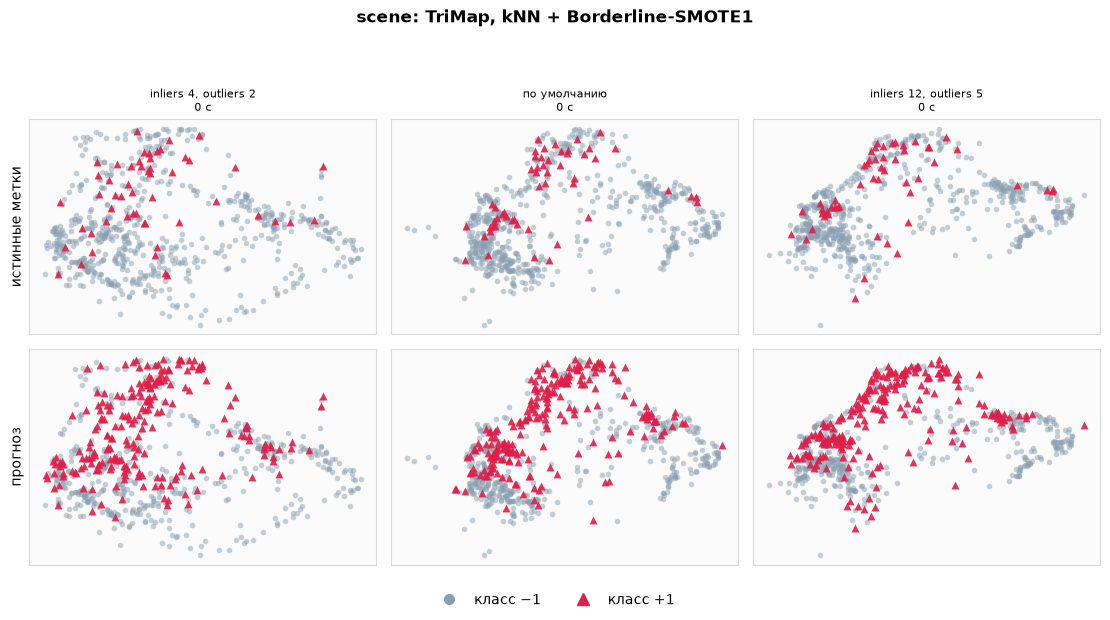

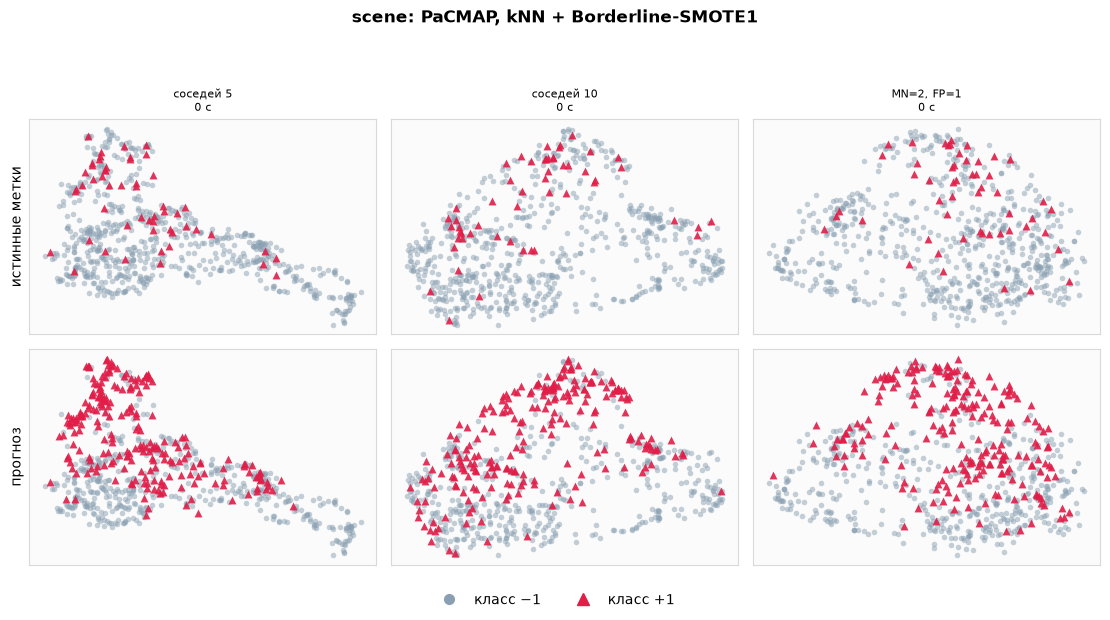

In [ ]:
## Теперь отрисовываем результаты 30% тестовой выборки и сраваниваем истенные метки с прогнозами модели

## Первая серия рисунков — для каждого классификатора и каждого метода. Берётся среднее из трёх сочетаний параметров. 
# Верхний ряд — известные классы теста, он одинаковый во всех столбцах. 
# Нижний ряд — прогноз модели, обученной с соответствующим сэмплингом.
# Затем для каждой выборки берем лучшую связку по Balanced Accuracy и вновь их отрисовываем
X_test_plot, y_test_plot = X_test_s, y_test
test_embeddings = compute_grid(X_test_plot, y_test_plot)

sampler_names = list(SAMPLERS)


def predictions_on_test(clf_name, sampler_name):
    model = fitted[(clf_name, sampler_name)]
    return model.predict(X_test)


for clf_name in CLF_NAMES:
    for method in METHODS:
        items = test_embeddings[method]
        label, Y, error, _seconds = items[len(items) // 2]
        if error or Y is None:
            print(f"{clf_name}, {method}: {error}")
            continue
        fig, axes = plt.subplots(2, len(sampler_names), figsize=(15.6, 5.6))
        for j, sampler_name in enumerate(sampler_names):
            draw(axes[0, j], Y, y_test_plot)
            if (clf_name, sampler_name) not in fitted:
                axes[1, j].text(0.5, 0.5, "нет модели", ha="center", va="center")
                axes[1, j].set_axis_off()
            else:
                draw(axes[1, j], Y, predictions_on_test(clf_name, sampler_name))
            axes[0, j].set_title(sampler_name, fontsize=8)
        axes[0, 0].set_ylabel("истинные метки")
        axes[1, 0].set_ylabel("прогноз")
        fig.suptitle(
            f"{DATASET_NAME}, {clf_name}, {method}: {label}",
            fontsize=12, fontweight="bold",
        )
        fig.tight_layout(rect=(0, 0.06, 1, 0.92))
        plt.show()

# Сочетания параметров вложения на лучшей по тесту модели.
best_row = hold_ok.sort_values(["Balanced Accuracy", "F1-score"], ascending=False).iloc[0]
best_clf = best_row["классификатор"]
best_sampler = best_row["сэмплинг"]
best_pred = predictions_on_test(best_clf, best_sampler)
print(
    f"Дальше параметры вложений показаны для {best_clf} + {best_sampler}: "
    f"BA {best_row['Balanced Accuracy']:.3f}, F1 {best_row['F1-score']:.3f}."
)

for method in METHODS:
    items = test_embeddings[method]
    fig, axes = plt.subplots(2, 3, figsize=(11.2, 6.2))
    for j in range(3):
        ax_true, ax_pred = axes[0, j], axes[1, j]
        if j >= len(items):
            ax_true.axis("off")
            ax_pred.axis("off")
            continue
        label, Y, error, seconds = items[j]
        if error or Y is None:
            ax_true.set_title(error, fontsize=7)
            ax_true.axis("off")
            ax_pred.axis("off")
            continue
        draw(ax_true, Y, y_test_plot)
        draw(ax_pred, Y, best_pred)
        ax_true.set_title(f"{label}\n{seconds:.0f} с", fontsize=8)
    axes[0, 0].set_ylabel("истинные метки")
    axes[1, 0].set_ylabel("прогноз")
    fig.suptitle(
        f"{DATASET_NAME}: {method}, {best_clf} + {best_sampler}",
        fontsize=12, fontweight="bold",
    )
    fig.tight_layout(rect=(0, 0.06, 1, 0.93))
    plt.show()


## Параметры алгоритмов сэмплинга

Перебираются параметры, которые есть в конструкторах этих классов, включая значения по умолчанию.
Для параметра, у которого в документации несколько типов, в переборе есть каждый тип.

У SMOTE и Borderline-SMOTE это `sampling_strategy` (float, str, dict, callable), `k_neighbors` (int и объект `NearestNeighbors`), у Borderline ещё `m_neighbors` тех же двух типов и `kind` со строками `borderline-1` и `borderline-2`.
У Instance Hardness Threshold — `sampling_strategy` тех же четырёх типов, `cv` как число и как `StratifiedKFold`, `estimator` как `None` и как объект классификатора, `n_jobs` как `None` и как int.
У SMOTETomek — `sampling_strategy`, объекты `smote` и `tomek` (в том числе `None`), `n_jobs`.
`random_state` проверяется и как целое, и как `RandomState`, и как `None`.

Связка из двух шагов перебирает параметры каждого шага по отдельности.
Качество снова считается на отложенном тесте, отдельно для kNN, SVM и леса.



SMOTE


  по умолчанию: −1=1560, +1=1560, 0.0 с


  sampling_strategy=0.4 (float): −1=1560, +1=624, 0.0 с


  sampling_strategy=0.8 (float): −1=1560, +1=1248, 0.0 с


  sampling_strategy='minority' (str): −1=1560, +1=1560, 0.0 с


...

  tomek=TomekLinks(sampling_strategy='majority') (object): −1=1560, +1=1560, 0.1 с


  random_state=RandomState(42): −1=1560, +1=1560, 0.1 с


  n_jobs=1 (int): −1=1560, +1=1560, 0.1 с


  n_jobs=None: −1=1560, +1=1560, 0.1 с


,алгоритм,параметры,классификатор,−1,+1,Balanced Accuracy,F1-score,секунды,ошибка
0,SMOTE,по умолчанию,kNN,1560.0,1560.0,0.6908,0.2332,0.01,
1,SMOTE,по умолчанию,SVM,1560.0,1560.0,0.6139,0.2857,0.01,
2,SMOTE,по умолчанию,RF,1560.0,1560.0,0.5794,0.2410,0.01,
3,SMOTE,sampling_strategy=0.4 (float),kNN,1560.0,624.0,0.7048,0.2734,0.01,
4,SMOTE,sampling_strategy=0.4 (float),SVM,1560.0,624.0,0.6300,0.3299,0.01,
...,...,...,...,...,...,...,...,...,...
151,SMOTETomek,n_jobs=1 (int),SVM,1560.0,1560.0,0.6139,0.2857,0.07,
152,SMOTETomek,n_jobs=1 (int),RF,1560.0,1560.0,0.5794,0.2410,0.07,
153,SMOTETomek,n_jobs=None,kNN,1560.0,1560.0,0.6908,0.2332,0.07,
154,SMOTETomek,n_jobs=None,SVM,1560.0,1560.0,0.6139,0.2857,0.07,


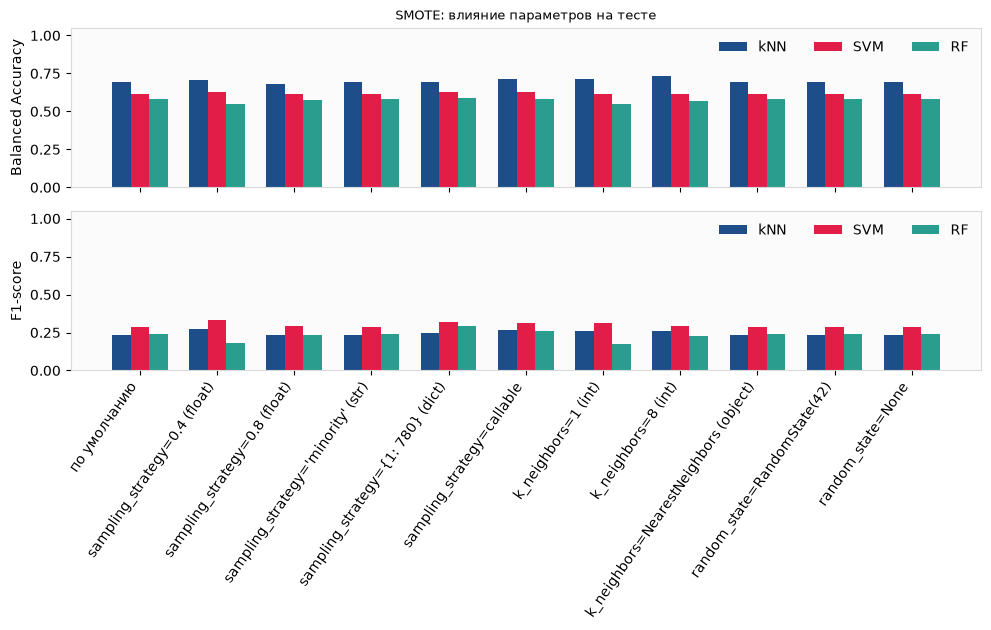

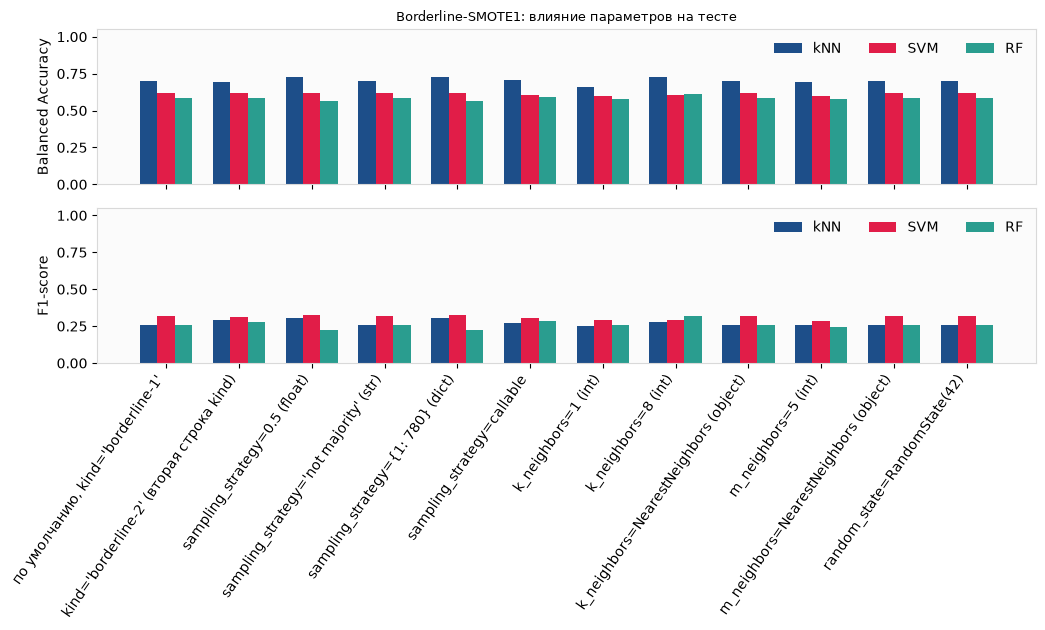

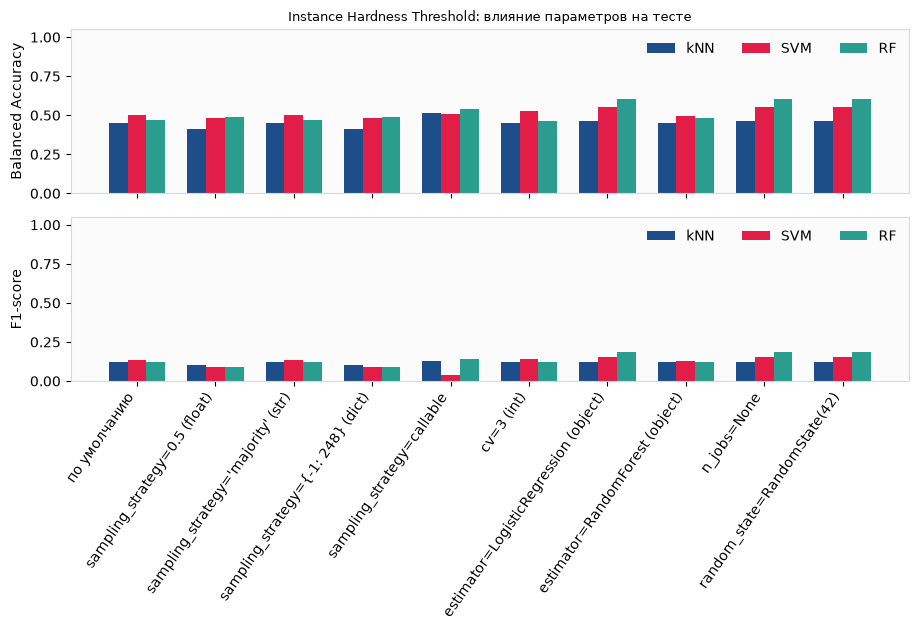

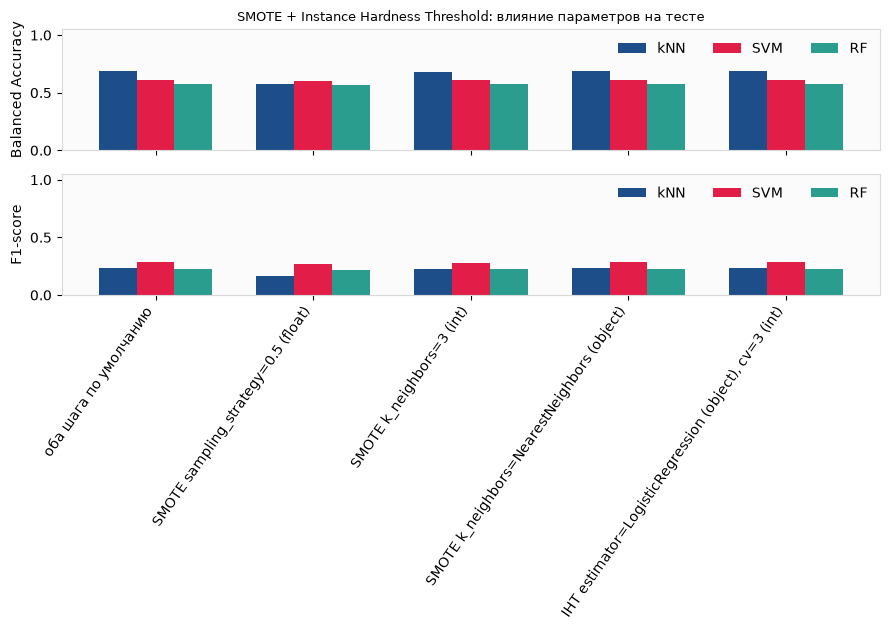

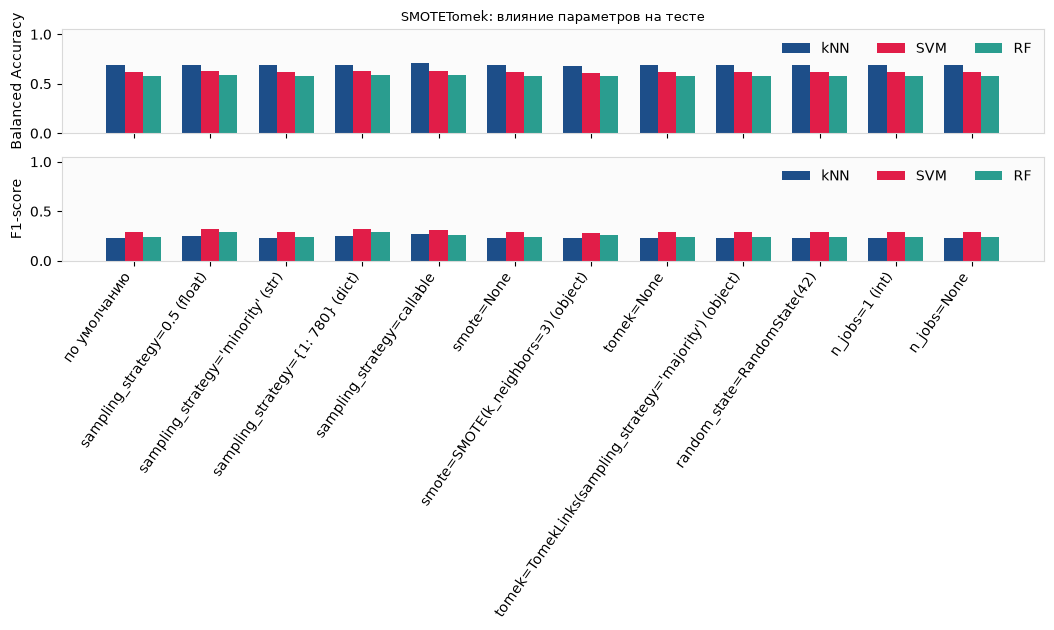

In [ ]:
# Теперь сравниваем семплинг с разными параметры, 
# тут же их задем, сэмплинг на обучающей, на тестовой опять учатся SVM KNN и лесочек
n_min = int(np.sum(y_train == 1))
n_maj = int(np.sum(y_train == -1))
half_min = max(n_min, int(round(0.5 * n_maj)))
keep_maj = min(n_maj, max(n_min, int(round(n_min / 0.5))))
k_hi = max(1, min(8, n_min - 2))
# У объекта NearestNeighbors соседей на одного больше, чем у целого k_neighbors:
# SMOTE отбрасывает первую найденную точку, это сам объект.
cv_object = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

parameter_groups = []

parameter_groups.append(("SMOTE", [
    ("по умолчанию", lambda: SMOTE(random_state=SEED)),
    ("sampling_strategy=0.4 (float)", lambda: SMOTE(sampling_strategy=0.4, random_state=SEED)),
    ("sampling_strategy=0.8 (float)", lambda: SMOTE(sampling_strategy=0.8, random_state=SEED)),
    ("sampling_strategy='minority' (str)", lambda: SMOTE(sampling_strategy="minority", random_state=SEED)),
    (f"sampling_strategy={{1: {half_min}}} (dict)", lambda: SMOTE(sampling_strategy={1: half_min}, random_state=SEED)),
    ("sampling_strategy=callable", lambda: SMOTE(sampling_strategy=over_ratio(0.6), random_state=SEED)),
    ("k_neighbors=1 (int)", lambda: SMOTE(k_neighbors=1, random_state=SEED)),
    (f"k_neighbors={k_hi} (int)", lambda: SMOTE(k_neighbors=k_hi, random_state=SEED)),
    ("k_neighbors=NearestNeighbors (object)", lambda: SMOTE(k_neighbors=NearestNeighbors(n_neighbors=6), random_state=SEED)),
    ("random_state=RandomState(42)", lambda: SMOTE(random_state=np.random.RandomState(SEED))),
    ("random_state=None", lambda: SMOTE(random_state=None)),
]))

parameter_groups.append(("Borderline-SMOTE1", [
    ("по умолчанию, kind='borderline-1'", lambda: BorderlineSMOTE(kind="borderline-1", random_state=SEED)),
    ("kind='borderline-2' (вторая строка kind)", lambda: BorderlineSMOTE(kind="borderline-2", random_state=SEED)),
    ("sampling_strategy=0.5 (float)", lambda: BorderlineSMOTE(kind="borderline-1", sampling_strategy=0.5, random_state=SEED)),
    ("sampling_strategy='not majority' (str)", lambda: BorderlineSMOTE(kind="borderline-1", sampling_strategy="not majority", random_state=SEED)),
    (f"sampling_strategy={{1: {half_min}}} (dict)", lambda: BorderlineSMOTE(kind="borderline-1", sampling_strategy={1: half_min}, random_state=SEED)),
    ("sampling_strategy=callable", lambda: BorderlineSMOTE(kind="borderline-1", sampling_strategy=over_ratio(0.7), random_state=SEED)),
    ("k_neighbors=1 (int)", lambda: BorderlineSMOTE(kind="borderline-1", k_neighbors=1, random_state=SEED)),
    (f"k_neighbors={k_hi} (int)", lambda: BorderlineSMOTE(kind="borderline-1", k_neighbors=k_hi, random_state=SEED)),
    ("k_neighbors=NearestNeighbors (object)", lambda: BorderlineSMOTE(kind="borderline-1", k_neighbors=NearestNeighbors(n_neighbors=6), random_state=SEED)),
    ("m_neighbors=5 (int)", lambda: BorderlineSMOTE(kind="borderline-1", m_neighbors=5, random_state=SEED)),
    ("m_neighbors=NearestNeighbors (object)", lambda: BorderlineSMOTE(kind="borderline-1", m_neighbors=NearestNeighbors(n_neighbors=11), random_state=SEED)),
    ("random_state=RandomState(42)", lambda: BorderlineSMOTE(kind="borderline-1", random_state=np.random.RandomState(SEED))),
]))


parameter_groups.append(("Instance Hardness Threshold", [
    ("по умолчанию", lambda: InstanceHardnessThreshold(random_state=SEED, n_jobs=1)),
    ("sampling_strategy=0.5 (float)", lambda: InstanceHardnessThreshold(sampling_strategy=0.5, random_state=SEED, n_jobs=1)),
    ("sampling_strategy='majority' (str)", lambda: InstanceHardnessThreshold(sampling_strategy="majority", random_state=SEED, n_jobs=1)),
    (f"sampling_strategy={{-1: {keep_maj}}} (dict)", lambda: InstanceHardnessThreshold(sampling_strategy={-1: keep_maj}, random_state=SEED, n_jobs=1)),
    ("sampling_strategy=callable", lambda: InstanceHardnessThreshold(sampling_strategy=under_ratio(0.3), random_state=SEED, n_jobs=1)),
    ("cv=3 (int)", lambda: InstanceHardnessThreshold(cv=3, random_state=SEED, n_jobs=1)),
    ("cv=StratifiedKFold (object)", lambda: InstanceHardnessThreshold(cv=cv_object, random_state=SEED, n_jobs=1)),
    ("estimator=LogisticRegression (object)", lambda: InstanceHardnessThreshold(estimator=LogisticRegression(max_iter=500), random_state=SEED, n_jobs=1)),
    ("estimator=RandomForest (object)", lambda: InstanceHardnessThreshold(estimator=RandomForestClassifier(n_estimators=40, random_state=SEED, n_jobs=1), random_state=SEED, n_jobs=1)),
    ("n_jobs=None", lambda: InstanceHardnessThreshold(estimator=LogisticRegression(max_iter=500), random_state=SEED, n_jobs=None)),
    ("random_state=RandomState(42)", lambda: InstanceHardnessThreshold(estimator=LogisticRegression(max_iter=500), random_state=np.random.RandomState(SEED), n_jobs=1)),
]))



parameter_groups.append(("SMOTE + Instance Hardness Threshold", [
    ("оба шага по умолчанию", lambda: [
        ("smote", SMOTE(random_state=SEED)),
        ("iht", InstanceHardnessThreshold(random_state=SEED, n_jobs=1)),
    ]),
    ("SMOTE sampling_strategy=0.5 (float)", lambda: [
        ("smote", SMOTE(sampling_strategy=0.5, random_state=SEED)),
        ("iht", InstanceHardnessThreshold(random_state=SEED, n_jobs=1)),
    ]),
    ("SMOTE k_neighbors=3 (int)", lambda: [
        ("smote", SMOTE(k_neighbors=3, random_state=SEED)),
        ("iht", InstanceHardnessThreshold(random_state=SEED, n_jobs=1)),
    ]),
    ("SMOTE k_neighbors=NearestNeighbors (object)", lambda: [
        ("smote", SMOTE(k_neighbors=NearestNeighbors(n_neighbors=6), random_state=SEED)),
        ("iht", InstanceHardnessThreshold(random_state=SEED, n_jobs=1)),
    ]),
    ("IHT estimator=LogisticRegression (object), cv=3 (int)", lambda: [
        ("smote", SMOTE(random_state=SEED)),
        ("iht", InstanceHardnessThreshold(estimator=LogisticRegression(max_iter=500), cv=3, random_state=SEED, n_jobs=1)),
    ]),
    ("IHT sampling_strategy=0.5 (float)", lambda: [
        ("smote", SMOTE(random_state=SEED)),
        ("iht", InstanceHardnessThreshold(sampling_strategy=0.5, random_state=SEED, n_jobs=1)),
    ]),
]))



parameter_groups.append(("SMOTETomek", [
    ("по умолчанию", lambda: SMOTETomek(random_state=SEED)),
    ("sampling_strategy=0.5 (float)", lambda: SMOTETomek(sampling_strategy=0.5, random_state=SEED)),
    ("sampling_strategy='minority' (str)", lambda: SMOTETomek(sampling_strategy="minority", random_state=SEED)),
    (f"sampling_strategy={{1: {half_min}}} (dict)", lambda: SMOTETomek(sampling_strategy={1: half_min}, random_state=SEED)),
    ("sampling_strategy=callable", lambda: SMOTETomek(sampling_strategy=over_ratio(0.6), random_state=SEED)),
    ("smote=None", lambda: SMOTETomek(smote=None, random_state=SEED)),
    ("smote=SMOTE(k_neighbors=3) (object)", lambda: SMOTETomek(smote=SMOTE(k_neighbors=3, random_state=SEED), random_state=SEED)),
    ("tomek=None", lambda: SMOTETomek(tomek=None, random_state=SEED)),
    ("tomek=TomekLinks(sampling_strategy='majority') (object)", lambda: SMOTETomek(tomek=TomekLinks(sampling_strategy="majority"), random_state=SEED)),
    ("random_state=RandomState(42)", lambda: SMOTETomek(random_state=np.random.RandomState(SEED))),
    ("n_jobs=1 (int)", lambda: SMOTETomek(random_state=SEED, n_jobs=1)),
    ("n_jobs=None", lambda: SMOTETomek(random_state=SEED, n_jobs=None)),
]))


param_rows = []
for group_name, configs in parameter_groups:
    print(f"\n{group_name}")
    for config_name, factory in configs:
        started = time.time()
        try:
            X_res, y_res = apply_sampler(factory(), X_train_s, y_train)
            sample_error = ""
        except Exception as exc:
            sample_error = f"{type(exc).__name__}: {exc}"
            X_res, y_res = None, None
        sample_seconds = time.time() - started
        n_res_maj = n_res_min = np.nan
        if not sample_error:
            n_res_maj, n_res_min = class_counts(y_res)
        for clf_name in CLF_NAMES:
            if sample_error:
                ba = f1v = np.nan
                error = sample_error
            else:
                try:
                    clf = clf_factory(clf_name)
                    clf.fit(X_res, y_res)
                    ba, f1v = metric_pair(y_test, clf.predict(X_test_s))
                    error = ""
                except Exception as exc:
                    ba = f1v = np.nan
                    error = f"{type(exc).__name__}: {exc}"
            param_rows.append({
                "алгоритм": group_name,
                "параметры": config_name,
                "классификатор": clf_name,
                "−1": n_res_maj,
                "+1": n_res_min,
                "Balanced Accuracy": ba,
                "F1-score": f1v,
                "секунды": round(sample_seconds, 2),
                "ошибка": error,
            })
        if sample_error:
            print(f"  {config_name}: {sample_error}")
        else:
            print(f"  {config_name}: −1={n_res_maj}, +1={n_res_min}, {sample_seconds:.1f} с")

param_table = pd.DataFrame(param_rows)
display(param_table.round(4))

for group_name, _configs in parameter_groups:
    part = param_table[param_table["алгоритм"] == group_name].dropna(subset=["Balanced Accuracy"])
    if part.empty:
        print(f"{group_name}: ни одна настройка не дала выборку")
        continue
    configs = list(dict.fromkeys(part["параметры"]))
    fig, axes = plt.subplots(2, 1, figsize=(max(9, 0.72 * len(configs) + 2), 6.4), sharex=True)
    x = np.arange(len(configs))
    width = 0.24
    for ax, metric in zip(axes, ("Balanced Accuracy", "F1-score")):
        for shift, clf_name, color in ((-width, "kNN", "#1d4e89"), (0, "SVM", "#e11d48"), (width, "RF", "#2a9d8f")):
            vals = []
            for config_name in configs:
                cell = part[(part["параметры"] == config_name) & (part["классификатор"] == clf_name)]
                vals.append(float(cell[metric].iloc[0]) if len(cell) else np.nan)
            ax.bar(x + shift, vals, width, label=clf_name, color=color)
        ax.set_ylim(0, 1.05)
        ax.set_ylabel(metric)
        ax.legend(frameon=False, ncol=3)
    axes[1].set_xticks(x, configs, rotation=55, ha="right")
    axes[0].set_title(f"{group_name}: влияние параметров на тесте")
    fig.tight_layout()
    plt.show()


## Выводы

Без сэмплинга все три модели почти не находят редкий класс. Balanced Accuracy около 0.5, F1 близка к нулю: модель в основном говорит «класс −1».

SMOTE и Borderline-SMOTE1 это исправляют. На кросс-валидации сильнее всего вырастает kNN: balanced accuracy 0.53 => 0.69. На одном разбиении 70/30 лучший у всех трёх — Borderline-SMOTE1. F1 тоже растёт, но остаётся около 0.2–0.3: редкий класс находится чаще, зато появляются ложные срабатывания.

Instance Hardness Threshold выборку режет слишком сильно, до пары сотен объектов, и качество падает ниже обучения без сэмплинга. SMOTE+IHT и SMOTETomek по цифрам совпали со SMOTE: после выравнивания классов второму шагу уже нечего удалять.

Полное выравнивание до 1:1 не всегда лучшая точка. У Borderline-SMOTE1 доля 0.5 дала kNN результат выше, чем настройка по умолчанию. Число соседей у SMOTE двигает метрику слабо.
